## Business Context

Renewable energy sources play an increasingly important role in the global energy mix, as the effort to reduce the environmental impact of energy production increases.

Out of all the renewable energy alternatives, wind energy is one of the most developed technologies worldwide. The U.S Department of Energy has put together a guide to achieving operational efficiency using predictive maintenance practices.

Predictive maintenance uses sensor information and analysis methods to measure and predict degradation and future component capability. The idea behind predictive maintenance is that failure patterns are predictable and if component failure can be predicted accurately and the component is replaced before it fails, the costs of operation and maintenance will be much lower.

The sensors fitted across different machines involved in the process of energy generation collect data related to various environmental factors (temperature, humidity, wind speed, etc.) and additional features related to various parts of the wind turbine (gearbox, tower, blades, break, etc.).

## Objective
“ReneWind” is a company working on improving the machinery/processes involved in the production of wind energy using machine learning and has collected data of generator failure of wind turbines using sensors. They have shared a ciphered version of the data, as the data collected through sensors is confidential (the type of data collected varies with companies). Data has 40 predictors, 20000 observations in the training set and 5000 in the test set.

The objective is to build various classification models, tune them, and find the best one that will help identify failures so that the generators could be repaired before failing/breaking to reduce the overall maintenance cost.
The nature of predictions made by the classification model will translate as follows:

- True positives (TP) are failures correctly predicted by the model. These will result in repairing costs.
- False negatives (FN) are real failures where there is no detection by the model. These will result in replacement costs.
- False positives (FP) are detections where there is no failure. These will result in inspection costs.

It is given that the cost of repairing a generator is much less than the cost of replacing it, and the cost of inspection is less than the cost of repair.

“1” in the target variables should be considered as “failure” and “0” represents “No failure”.



## Data Description
- The data provided is a transformed version of original data which was collected using sensors.
- Train.csv - To be used for training and tuning of models.
- Test.csv - To be used only for testing the performance of the final best model.
- Both the datasets consist of 40 predictor variables and 1 target variable

## Importing necessary libraries

In [1]:
#C1
# Mount Drive Short
from google.colab import drive
from pathlib import Path
drive.mount('/content/drive', force_remount=True)
%cd "./drive/MyDrive/Colab Notebooks/"

!ls

Mounted at /content/drive
/content/drive/MyDrive/Colab Notebooks
 CherryPicking-1.jpg
'Easy Visa'
'E-news Express'
'Food Hub'
'Inn Hotels'
 MT_Project_ReneWind_PresentationTemplate.pptx
 plots
 Project3_AdvancedPython
 ReCell
 reference
'ReneWind_ Model Tuning FAQ - Great Learning.pdf'
'ReneWind _ Problem Statement_ Model Tuning - Great Learning.pdf'
 ReneWind_ScottHorning_Portfolio.ipynb
 reports_db
 Test.csv
 Train.csv
 trash
 Volleyball
'WSJ Cherry Picking 001.ipynb'


In [87]:
 #C2
 #print the mark down table of contents.
 #Use to keep logical directon

import json


NB = Path("ReneWind_ScottHorning_Portfolio.ipynb")

nb = json.loads(NB.read_text())

for i, cell in enumerate(nb["cells"]):
    if cell["cell_type"] != "markdown":
        continue
    src = "".join(cell.get("source") or []).strip()
    if not src:
        continue
    first = src.splitlines()[0].rstrip()
    hashes = 0
    for ch in first:
        if ch == "#":
            hashes = hashes + 1
        else:
            break
    level = hashes if hashes > 0 else 0
    indent = "  " * max(level - 1, 0)
    print(f"{i:03d}  {indent}{first[:100]}")

000    ## Business Context
001    ## Objective
002    ## Data Description
003    ## Importing necessary libraries
007    ## Loading the dataset
018      ### Data Overview
019    ##Function Listing
021    ## Exploratory Data Analysis (EDA)
022      ### Plotting histograms and boxplots for all the variables train
024      ### Plotting all the features at one go for train data
026        #### No EDA on test data.
027        ####Univariate EDA
028    ## Data Pre-processing
033        ####Data Pre-Processing
034    ## Missing value imputation
036  The nature of predictions made by the classification model will translate as follows:
037    ## Model evaluation criterion
038    ## Model Building
039      ###define a function to output different metrics (including recall) on the train and test set
041      ###define a function to show confusion matrix so that we do not have to use the same code repetitive
043      ###Defining scorer to be used for cross-validation and hyperparameter tuning
044 

In [3]:
#C3
#  Libraries to help with reading and manipulating data
import pandas as pd
import numpy as np

# Libaries to help with data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# To tune model, get different metric scores, and split data
from sklearn.metrics import (
    f1_score,
    accuracy_score,
    recall_score,
    precision_score,
    confusion_matrix,
    roc_auc_score,
    ConfusionMatrixDisplay,
)
from sklearn import metrics

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score

# To be used for data scaling and one hot encoding
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder

# To impute missing values
from sklearn.impute import SimpleImputer

# To oversample and undersample data
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

# To do hyperparameter tuning
from sklearn.model_selection import RandomizedSearchCV

# To be used for creating pipelines and personalizing them
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

# To define maximum number of columns to be displayed in a dataframe
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)

# To supress scientific notations for a dataframe
pd.set_option("display.float_format", lambda x: "%.3f" % x)

# To help with model building
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    AdaBoostClassifier,
    GradientBoostingClassifier,
    RandomForestClassifier,
    BaggingClassifier,
)
from xgboost import XGBClassifier


# To suppress warnings
import warnings

warnings.filterwarnings("ignore")

# This will help in making the Python code more structured automatically (good coding practice)
#%load_ext nb_black

## Loading the dataset

In [4]:
#C4
df = pd.read_csv('Train.csv')
df_backup = df.copy()
df_test = pd.read_csv('Test.csv')

In [5]:
#C5 checking shape of the data
print("The training set has ", df.shape[0], 'rows and', df.shape[1], "columns.")

The training set has  20000 rows and 41 columns.


In [6]:
#C6
#  checking shape of the data
print("The TEST set has ", df_test.shape[0], 'rows and', df.shape[1], "columns.")

The TEST set has  5000 rows and 41 columns.


In [7]:
#C7
# check training set for duplicates
df.duplicated().sum()

np.int64(0)

In [8]:
#C8
# check TEST set for duplicates
df_test.duplicated().sum()

np.int64(0)

In [9]:
#C9 Check training set for missing values in the data
print(df.isnull().sum())

V1        18
V2        18
V3         0
V4         0
V5         0
V6         0
V7         0
V8         0
V9         0
V10        0
V11        0
V12        0
V13        0
V14        0
V15        0
V16        0
V17        0
V18        0
V19        0
V20        0
V21        0
V22        0
V23        0
V24        0
V25        0
V26        0
V27        0
V28        0
V29        0
V30        0
V31        0
V32        0
V33        0
V34        0
V35        0
V36        0
V37        0
V38        0
V39        0
V40        0
Target     0
dtype: int64


In [10]:
# C9
# Check training set for missing values in the data
print(df_test.isnull().sum())

V1        5
V2        6
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
V29       0
V30       0
V31       0
V32       0
V33       0
V34       0
V35       0
V36       0
V37       0
V38       0
V39       0
V40       0
Target    0
dtype: int64


In [11]:
#C10
#  A concise summary of the DataFrame
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 41 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   V1      19982 non-null  float64
 1   V2      19982 non-null  float64
 2   V3      20000 non-null  float64
 3   V4      20000 non-null  float64
 4   V5      20000 non-null  float64
 5   V6      20000 non-null  float64
 6   V7      20000 non-null  float64
 7   V8      20000 non-null  float64
 8   V9      20000 non-null  float64
 9   V10     20000 non-null  float64
 10  V11     20000 non-null  float64
 11  V12     20000 non-null  float64
 12  V13     20000 non-null  float64
 13  V14     20000 non-null  float64
 14  V15     20000 non-null  float64
 15  V16     20000 non-null  float64
 16  V17     20000 non-null  float64
 17  V18     20000 non-null  float64
 18  V19     20000 non-null  float64
 19  V20     20000 non-null  float64
 20  V21     20000 non-null  float64
 21  V22     20000 non-null  float64
 22

In [12]:
#C11
#  A concise summary of the DataFrame
print(df_test.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 41 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   V1      4995 non-null   float64
 1   V2      4994 non-null   float64
 2   V3      5000 non-null   float64
 3   V4      5000 non-null   float64
 4   V5      5000 non-null   float64
 5   V6      5000 non-null   float64
 6   V7      5000 non-null   float64
 7   V8      5000 non-null   float64
 8   V9      5000 non-null   float64
 9   V10     5000 non-null   float64
 10  V11     5000 non-null   float64
 11  V12     5000 non-null   float64
 12  V13     5000 non-null   float64
 13  V14     5000 non-null   float64
 14  V15     5000 non-null   float64
 15  V16     5000 non-null   float64
 16  V17     5000 non-null   float64
 17  V18     5000 non-null   float64
 18  V19     5000 non-null   float64
 19  V20     5000 non-null   float64
 20  V21     5000 non-null   float64
 21  V22     5000 non-null   float64
 22  

In [13]:
#C12
#  Statistical summary of the dataset : training
print(df.describe(include="all").T)

           count   mean   std     min    25%    50%    75%    max
V1     19982.000 -0.272 3.442 -11.876 -2.737 -0.748  1.840 15.493
V2     19982.000  0.440 3.151 -12.320 -1.641  0.472  2.544 13.089
V3     20000.000  2.485 3.389 -10.708  0.207  2.256  4.566 17.091
V4     20000.000 -0.083 3.432 -15.082 -2.348 -0.135  2.131 13.236
V5     20000.000 -0.054 2.105  -8.603 -1.536 -0.102  1.340  8.134
V6     20000.000 -0.995 2.041 -10.227 -2.347 -1.001  0.380  6.976
V7     20000.000 -0.879 1.762  -7.950 -2.031 -0.917  0.224  8.006
V8     20000.000 -0.548 3.296 -15.658 -2.643 -0.389  1.723 11.679
V9     20000.000 -0.017 2.161  -8.596 -1.495 -0.068  1.409  8.138
V10    20000.000 -0.013 2.193  -9.854 -1.411  0.101  1.477  8.108
V11    20000.000 -1.895 3.124 -14.832 -3.922 -1.921  0.119 11.826
V12    20000.000  1.605 2.930 -12.948 -0.397  1.508  3.571 15.081
V13    20000.000  1.580 2.875 -13.228 -0.224  1.637  3.460 15.420
V14    20000.000 -0.951 1.790  -7.739 -2.171 -0.957  0.271  5.671
V15    200

### Data Overview
1. V1 has 18 missing values in Train and 5 in Test.
2. V2 has 18 missing values in Train and 6 in Test.
3. Train has 20,000 rows; Test has 5,000 rows.
4. Both sets share the same columns: V1–V40 (ciphered sensors) + Target.
5. No duplicate records in either set.
6. All 40 predictors are float64; Target is int64 in both sets.

##Function Listing


In [14]:
#C13
def histogram_boxplot(data, feature, figsize=(10, 5), kde=False, bins=None,freetext=""):
    """
    Boxplot and histogram combined
    data: dataframe
    feature: dataframe column
    figsize: size of figure (default (15,10))
    kde: whether to show the density curve (default False)
    bins: number of bins for histogram (default None)
    """
    f2, (ax_box2, ax_hist2) = plt.subplots(
        nrows=2,  # Number of rows of the subplot grid= 2
        sharex=True,  # x-axis will be shared among all subplots
        gridspec_kw={"height_ratios": (0.25, 0.75)},
        figsize=figsize,
    )  # creating the 2 subplots
    sns.boxplot(
        data=data, x=feature, ax=ax_box2, showmeans=True, color="violet"
    )  # boxplot will be created and a triangle will indicate the mean value of the column
    sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2, bins=bins
    ) if bins else sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2
    )  # For histogram
    ax_hist2.axvline(
        data[feature].mean(), color="green", linestyle="--"
    )  # Add mean to the histogram
    ax_hist2.axvline(
        data[feature].median(), color="black", linestyle="-"
    )  # Add median to the histogram
    print (freetext, 'Boxplot and histogram for feature ' ,feature)
    plt.show()
    print(data[feature].describe())
    print ('***********************\n\n')



## Exploratory Data Analysis (EDA)

### Plotting histograms and boxplots for all the variables train

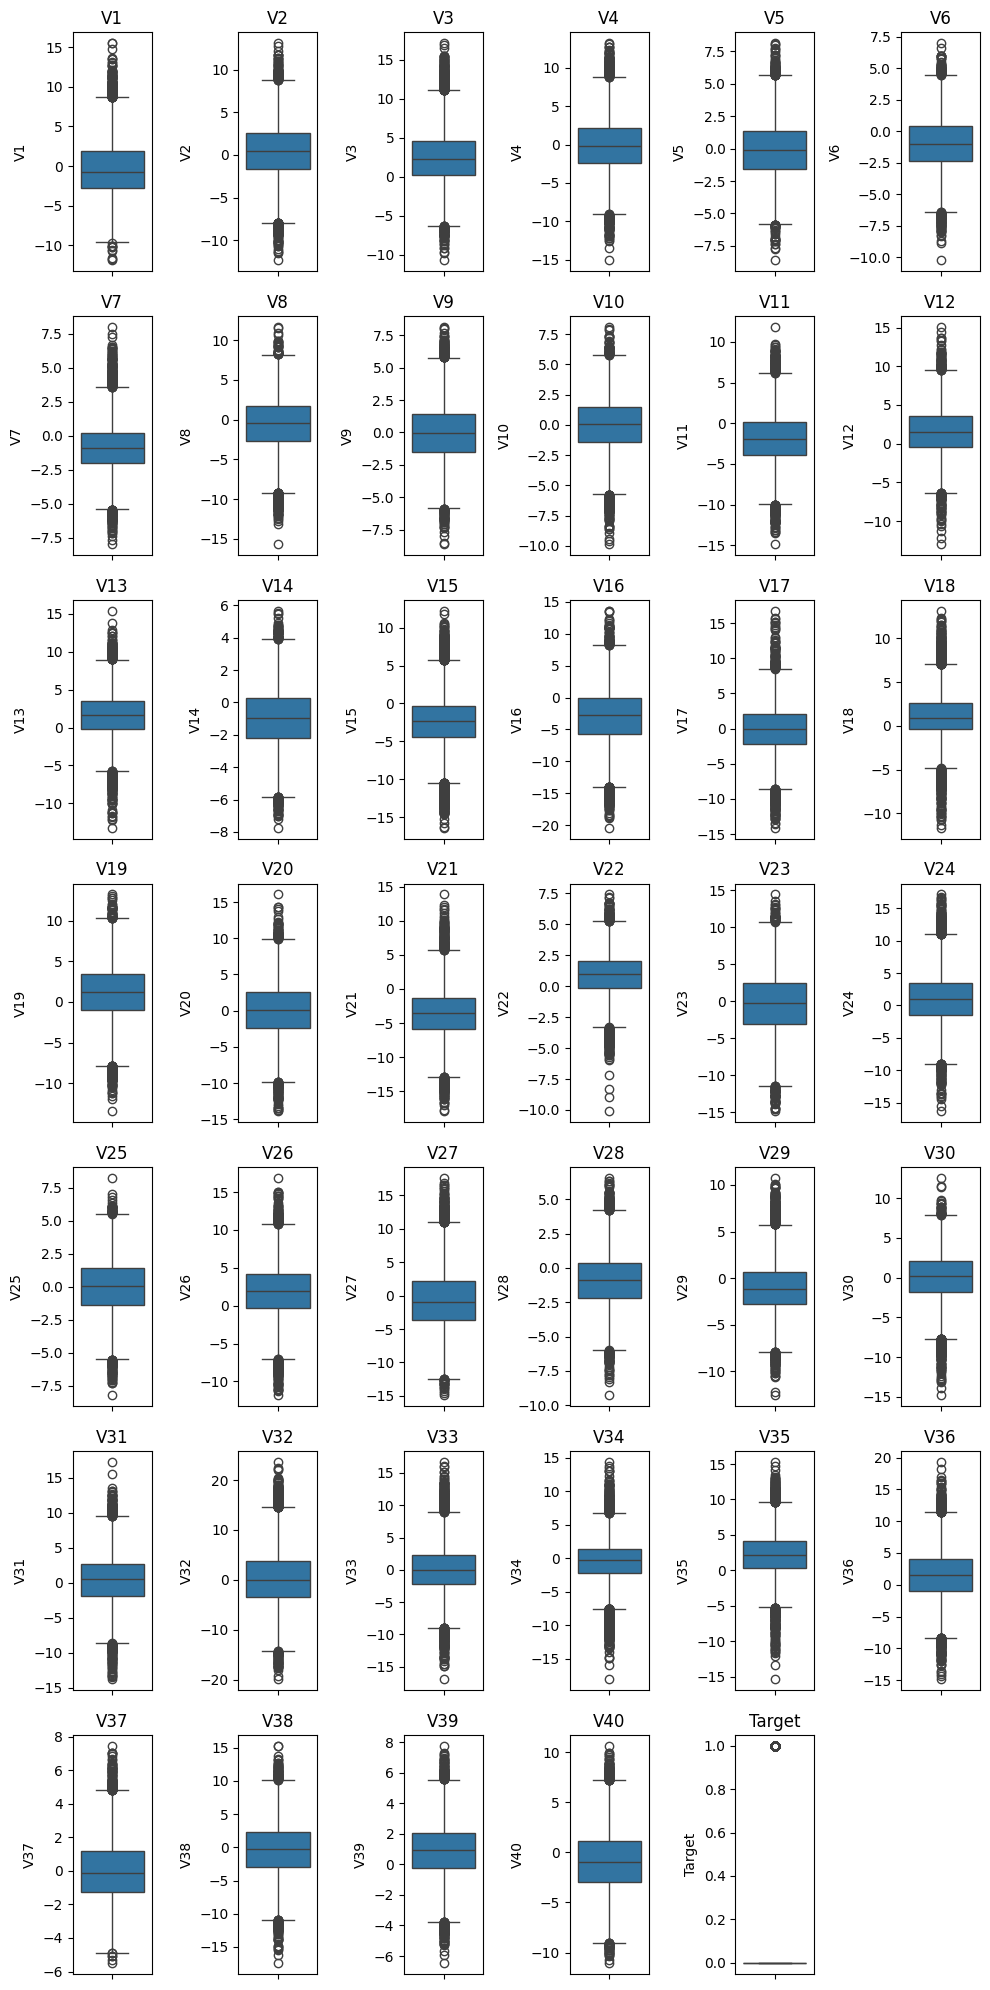

In [15]:
#C14
# a compact overview of training data
features = df.columns.tolist()

plt.figure(figsize=(10, 20))
for i, feature in enumerate(features):
    plt.subplot(7, 6, i + 1)
    sns.boxplot(df[feature])
    plt.tight_layout()
    plt.title(feature)
plt.show()

### Plotting all the features at one go for train data

training data :  Boxplot and histogram for feature  V1


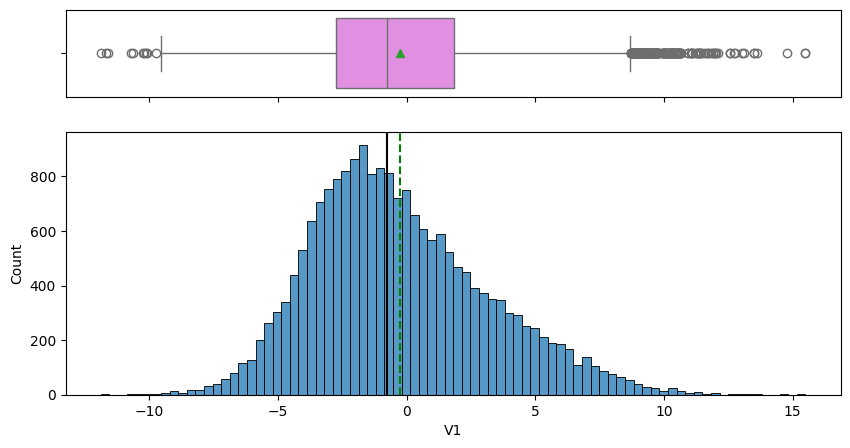

count   19982.000
mean       -0.272
std         3.442
min       -11.876
25%        -2.737
50%        -0.748
75%         1.840
max        15.493
Name: V1, dtype: float64
***********************


training data :  Boxplot and histogram for feature  V2


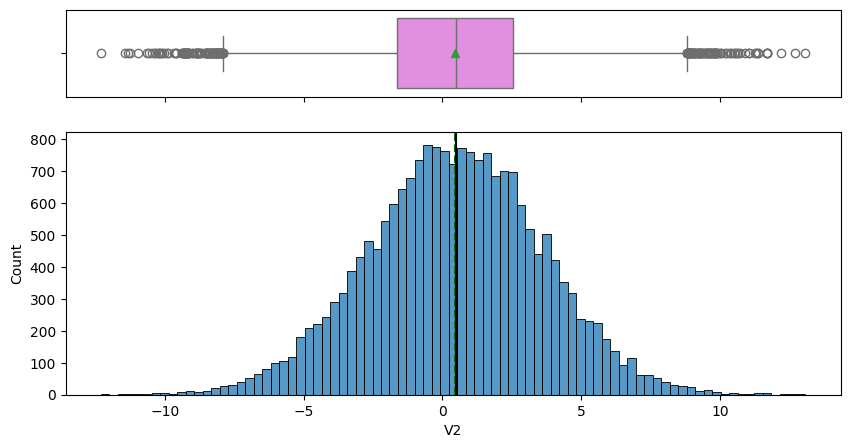

count   19982.000
mean        0.440
std         3.151
min       -12.320
25%        -1.641
50%         0.472
75%         2.544
max        13.089
Name: V2, dtype: float64
***********************


training data :  Boxplot and histogram for feature  V3


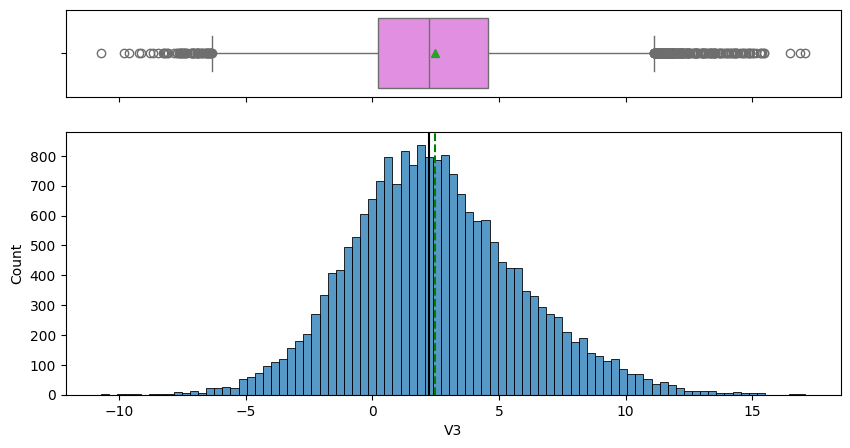

count   20000.000
mean        2.485
std         3.389
min       -10.708
25%         0.207
50%         2.256
75%         4.566
max        17.091
Name: V3, dtype: float64
***********************


training data :  Boxplot and histogram for feature  V4


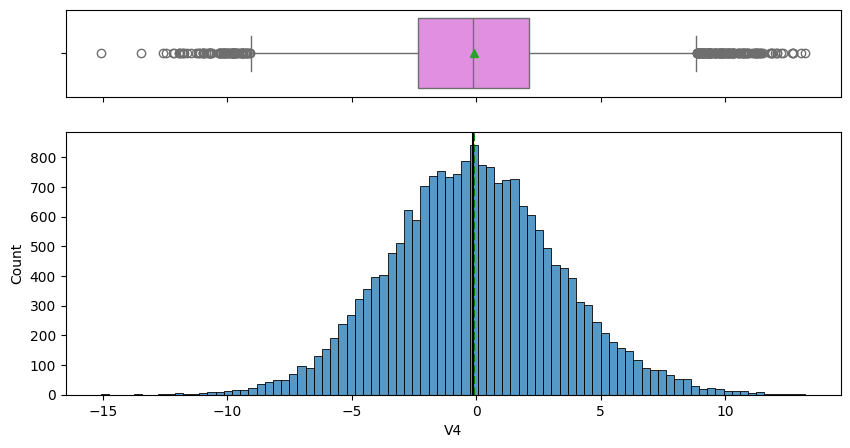

count   20000.000
mean       -0.083
std         3.432
min       -15.082
25%        -2.348
50%        -0.135
75%         2.131
max        13.236
Name: V4, dtype: float64
***********************


training data :  Boxplot and histogram for feature  V5


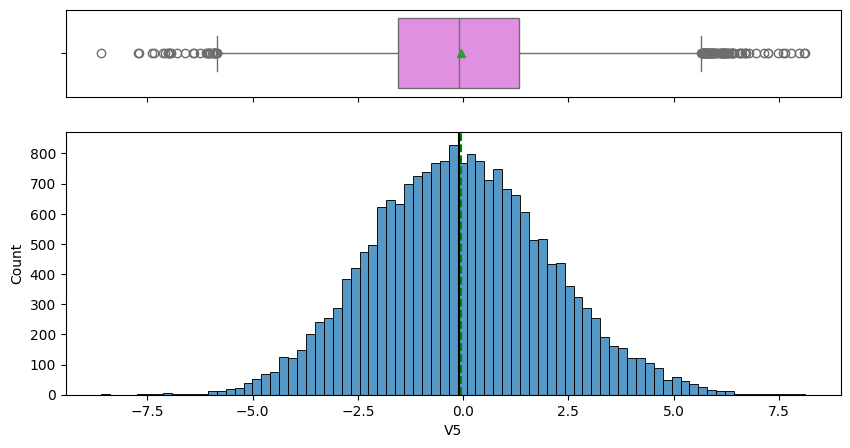

count   20000.000
mean       -0.054
std         2.105
min        -8.603
25%        -1.536
50%        -0.102
75%         1.340
max         8.134
Name: V5, dtype: float64
***********************


training data :  Boxplot and histogram for feature  V6


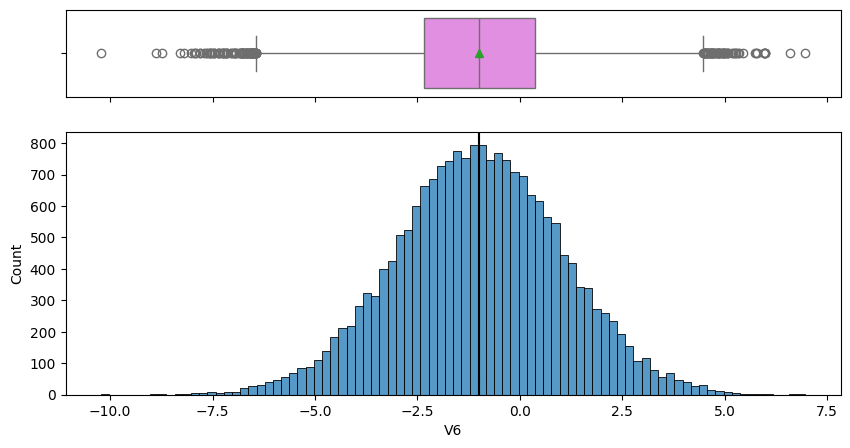

count   20000.000
mean       -0.995
std         2.041
min       -10.227
25%        -2.347
50%        -1.001
75%         0.380
max         6.976
Name: V6, dtype: float64
***********************


training data :  Boxplot and histogram for feature  V7


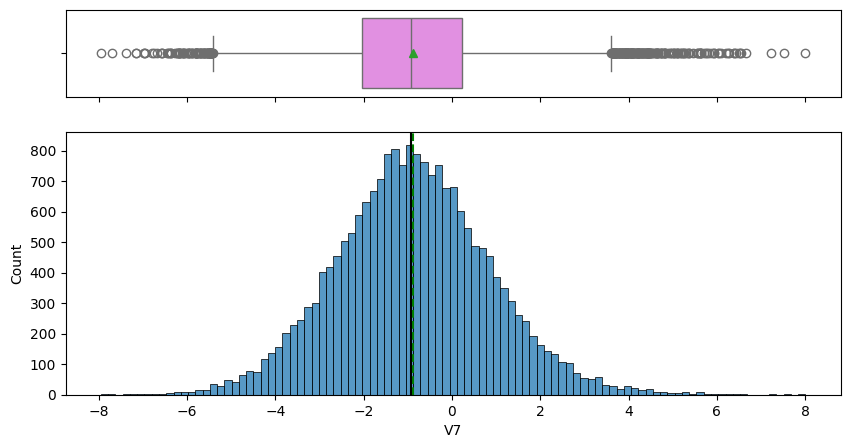

count   20000.000
mean       -0.879
std         1.762
min        -7.950
25%        -2.031
50%        -0.917
75%         0.224
max         8.006
Name: V7, dtype: float64
***********************


training data :  Boxplot and histogram for feature  V8


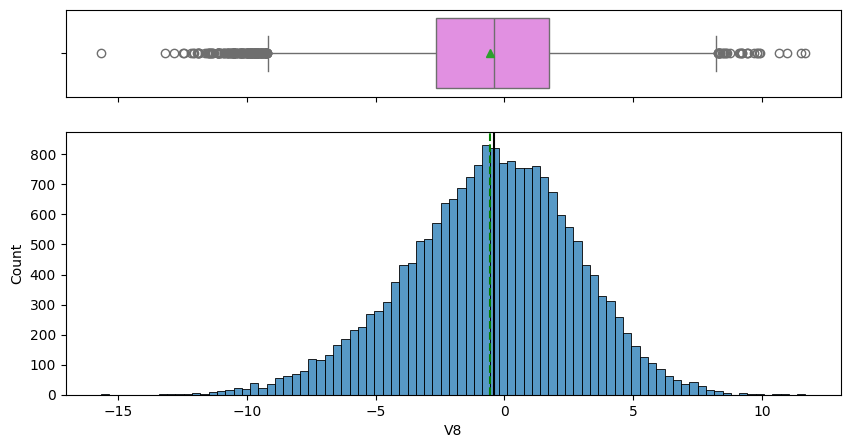

count   20000.000
mean       -0.548
std         3.296
min       -15.658
25%        -2.643
50%        -0.389
75%         1.723
max        11.679
Name: V8, dtype: float64
***********************


training data :  Boxplot and histogram for feature  V9


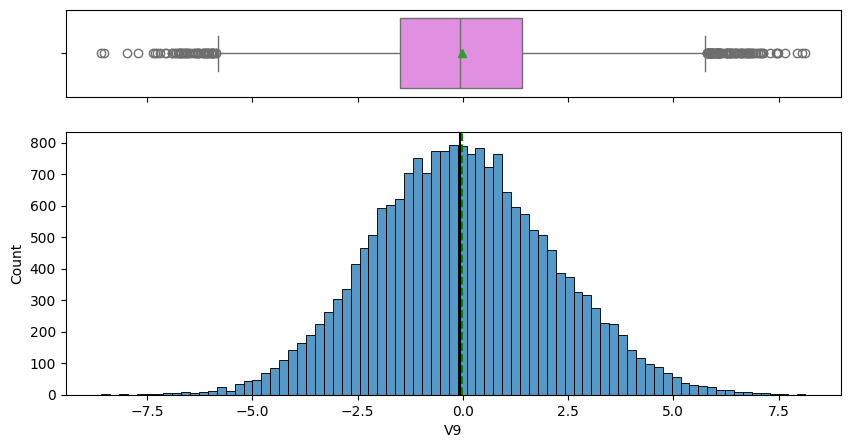

count   20000.000
mean       -0.017
std         2.161
min        -8.596
25%        -1.495
50%        -0.068
75%         1.409
max         8.138
Name: V9, dtype: float64
***********************


training data :  Boxplot and histogram for feature  V10


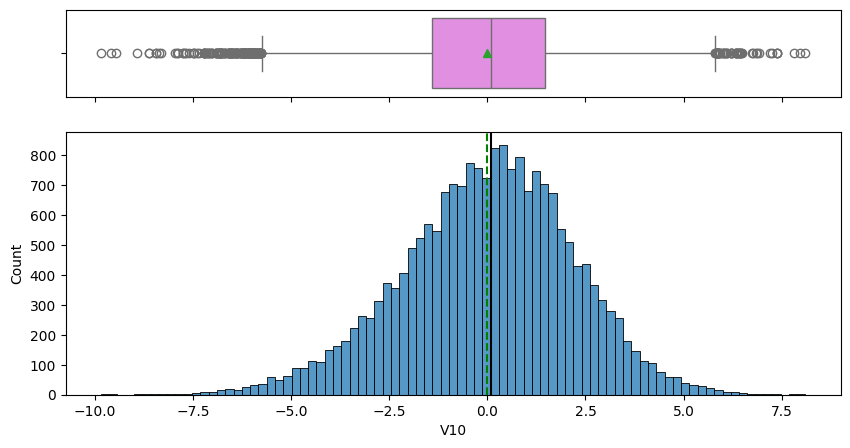

count   20000.000
mean       -0.013
std         2.193
min        -9.854
25%        -1.411
50%         0.101
75%         1.477
max         8.108
Name: V10, dtype: float64
***********************


training data :  Boxplot and histogram for feature  V11


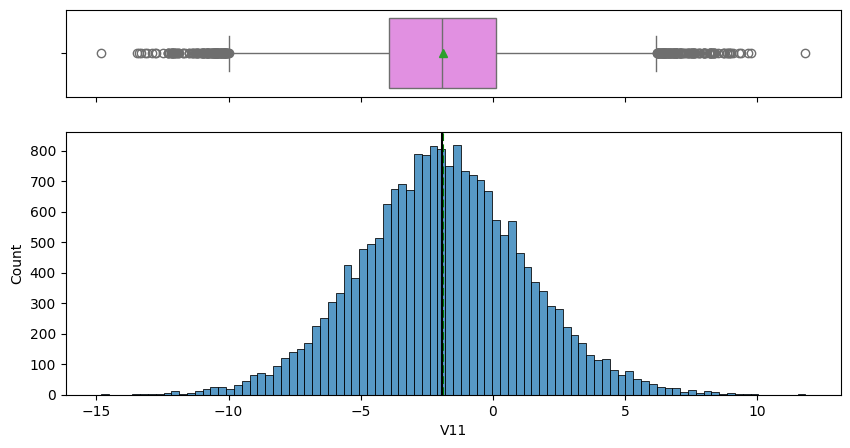

count   20000.000
mean       -1.895
std         3.124
min       -14.832
25%        -3.922
50%        -1.921
75%         0.119
max        11.826
Name: V11, dtype: float64
***********************


training data :  Boxplot and histogram for feature  V12


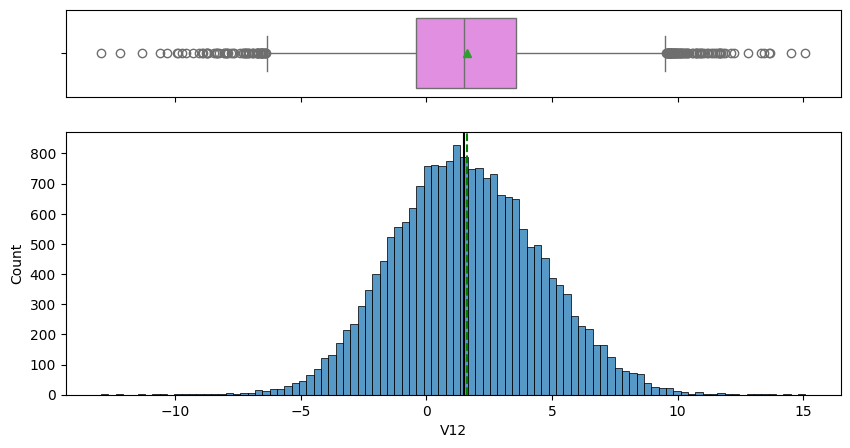

count   20000.000
mean        1.605
std         2.930
min       -12.948
25%        -0.397
50%         1.508
75%         3.571
max        15.081
Name: V12, dtype: float64
***********************


training data :  Boxplot and histogram for feature  V13


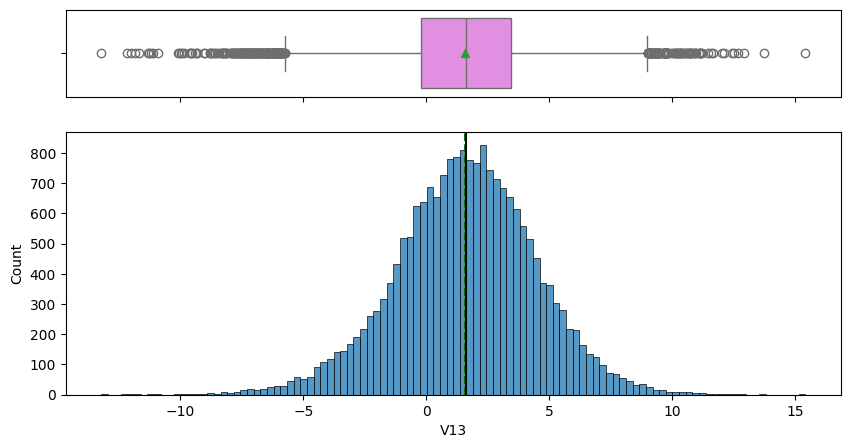

count   20000.000
mean        1.580
std         2.875
min       -13.228
25%        -0.224
50%         1.637
75%         3.460
max        15.420
Name: V13, dtype: float64
***********************


training data :  Boxplot and histogram for feature  V14


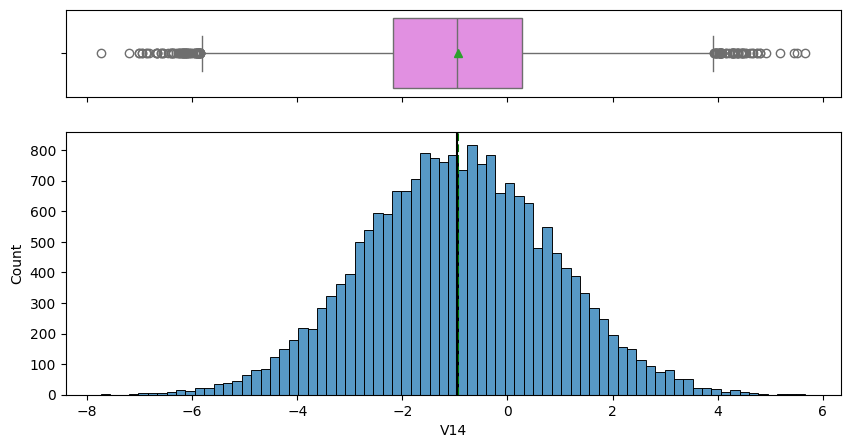

count   20000.000
mean       -0.951
std         1.790
min        -7.739
25%        -2.171
50%        -0.957
75%         0.271
max         5.671
Name: V14, dtype: float64
***********************


training data :  Boxplot and histogram for feature  V15


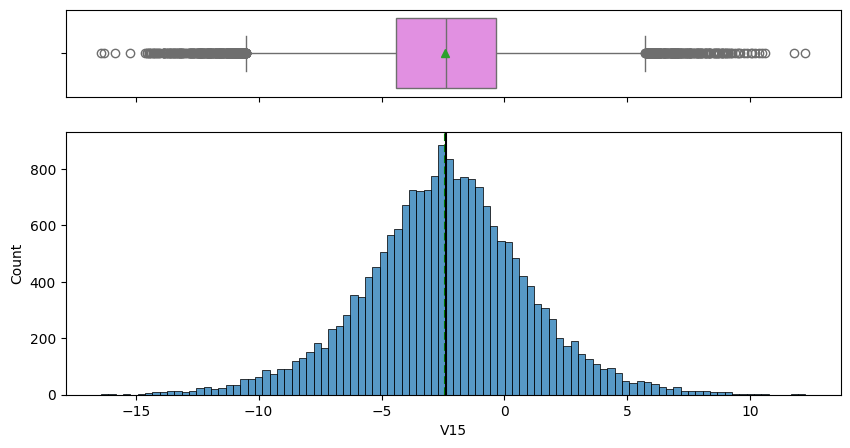

count   20000.000
mean       -2.415
std         3.355
min       -16.417
25%        -4.415
50%        -2.383
75%        -0.359
max        12.246
Name: V15, dtype: float64
***********************


training data :  Boxplot and histogram for feature  V16


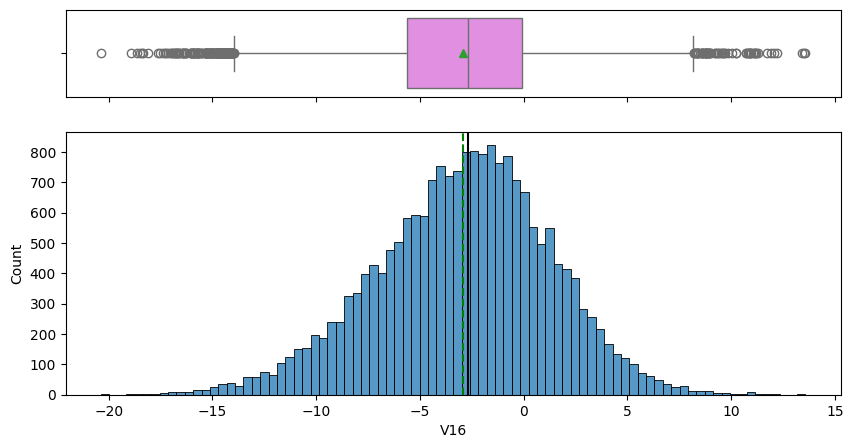

count   20000.000
mean       -2.925
std         4.222
min       -20.374
25%        -5.634
50%        -2.683
75%        -0.095
max        13.583
Name: V16, dtype: float64
***********************


training data :  Boxplot and histogram for feature  V17


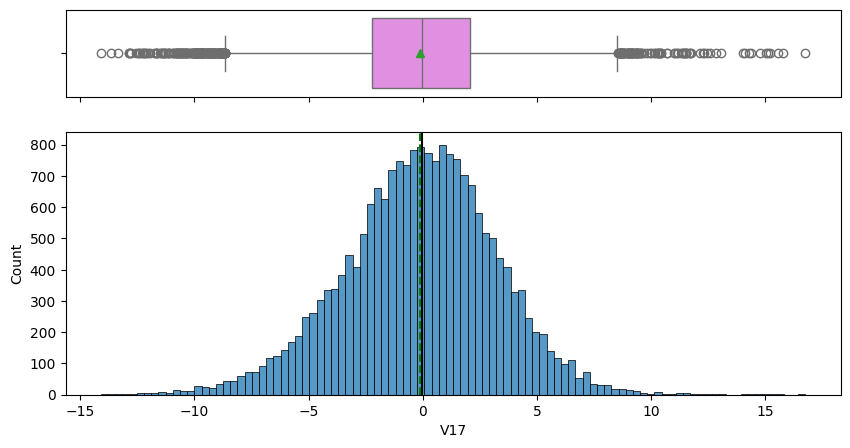

count   20000.000
mean       -0.134
std         3.345
min       -14.091
25%        -2.216
50%        -0.015
75%         2.069
max        16.756
Name: V17, dtype: float64
***********************


training data :  Boxplot and histogram for feature  V18


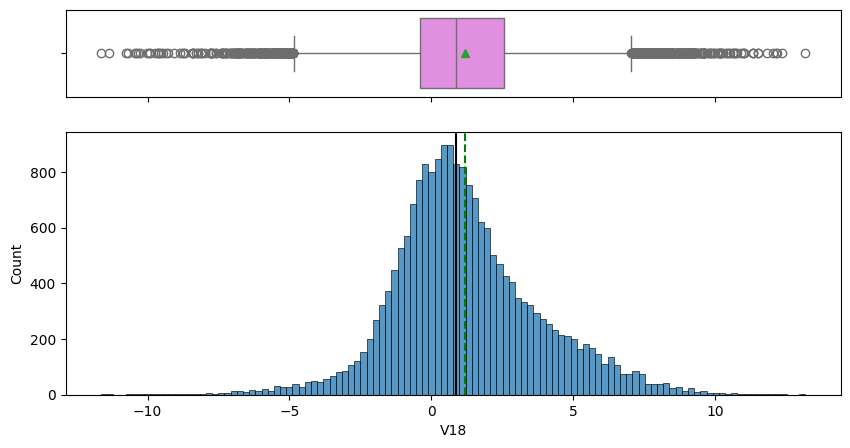

count   20000.000
mean        1.189
std         2.592
min       -11.644
25%        -0.404
50%         0.883
75%         2.572
max        13.180
Name: V18, dtype: float64
***********************


training data :  Boxplot and histogram for feature  V19


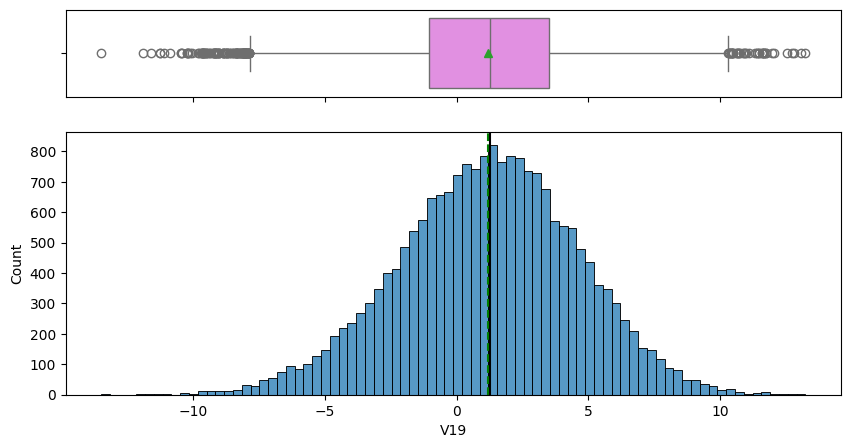

count   20000.000
mean        1.182
std         3.397
min       -13.492
25%        -1.050
50%         1.279
75%         3.493
max        13.238
Name: V19, dtype: float64
***********************


training data :  Boxplot and histogram for feature  V20


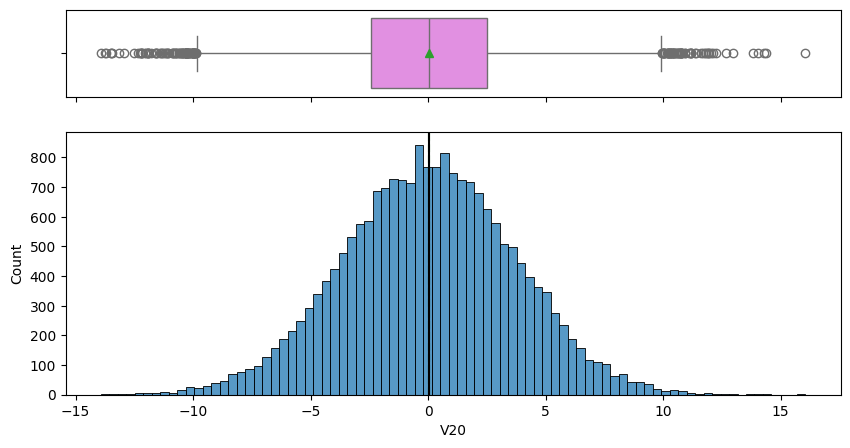

count   20000.000
mean        0.024
std         3.669
min       -13.923
25%        -2.433
50%         0.033
75%         2.512
max        16.052
Name: V20, dtype: float64
***********************


training data :  Boxplot and histogram for feature  V21


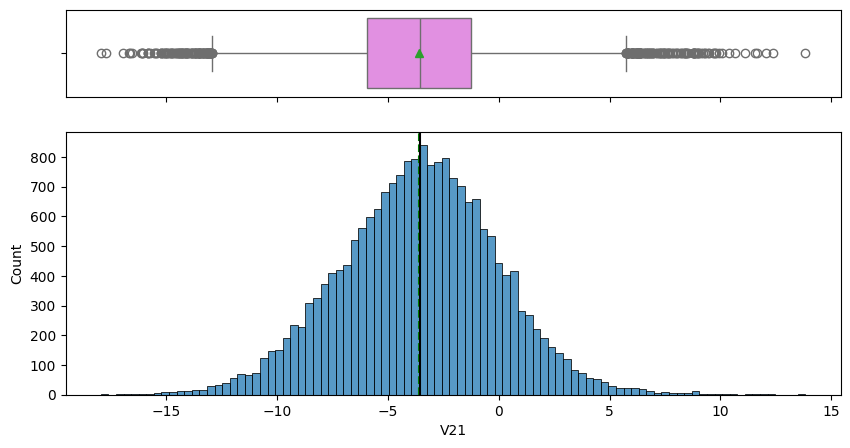

count   20000.000
mean       -3.611
std         3.568
min       -17.956
25%        -5.930
50%        -3.533
75%        -1.266
max        13.840
Name: V21, dtype: float64
***********************


training data :  Boxplot and histogram for feature  V22


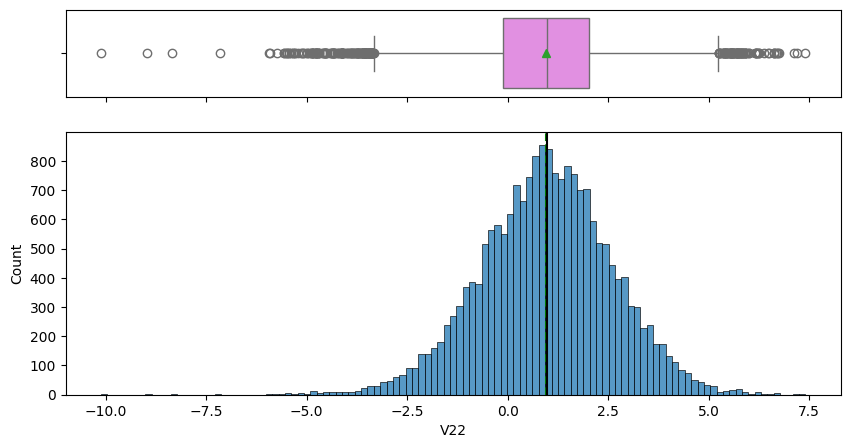

count   20000.000
mean        0.952
std         1.652
min       -10.122
25%        -0.118
50%         0.975
75%         2.026
max         7.410
Name: V22, dtype: float64
***********************


training data :  Boxplot and histogram for feature  V23


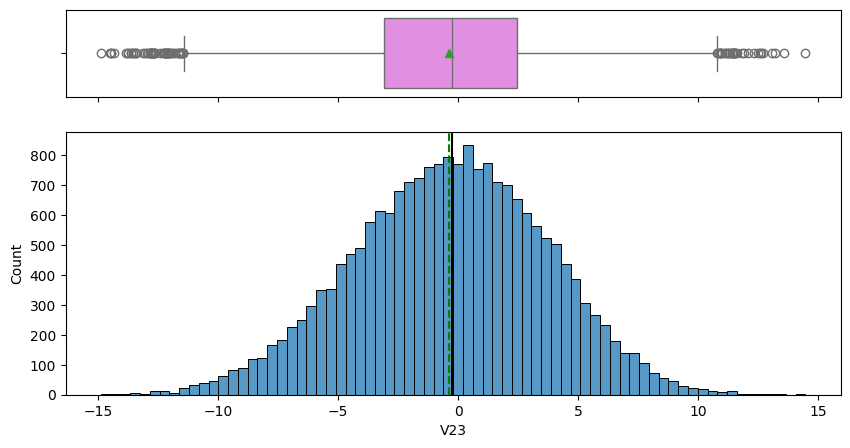

count   20000.000
mean       -0.366
std         4.032
min       -14.866
25%        -3.099
50%        -0.262
75%         2.452
max        14.459
Name: V23, dtype: float64
***********************


training data :  Boxplot and histogram for feature  V24


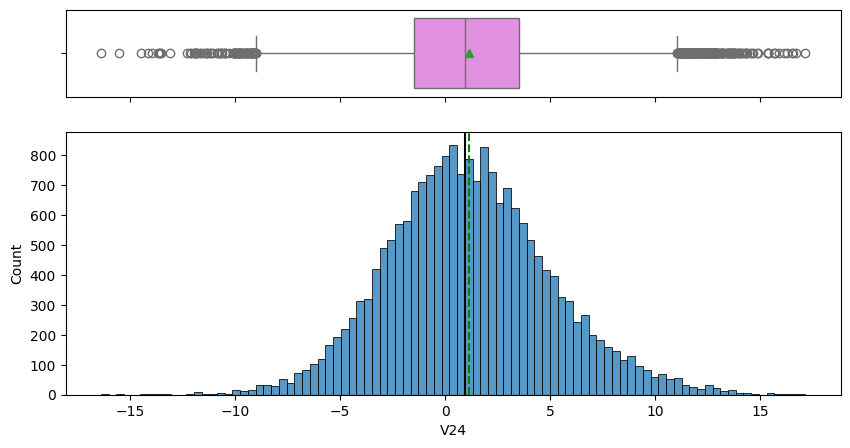

count   20000.000
mean        1.134
std         3.912
min       -16.387
25%        -1.468
50%         0.969
75%         3.546
max        17.163
Name: V24, dtype: float64
***********************


training data :  Boxplot and histogram for feature  V25


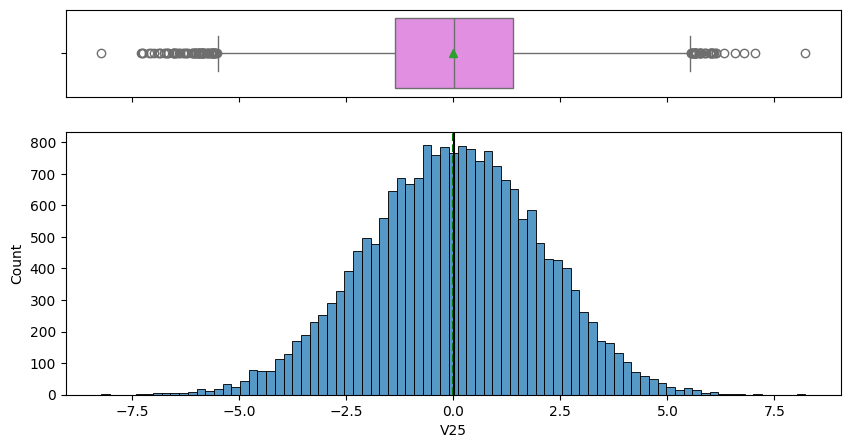

count   20000.000
mean       -0.002
std         2.017
min        -8.228
25%        -1.365
50%         0.025
75%         1.397
max         8.223
Name: V25, dtype: float64
***********************


training data :  Boxplot and histogram for feature  V26


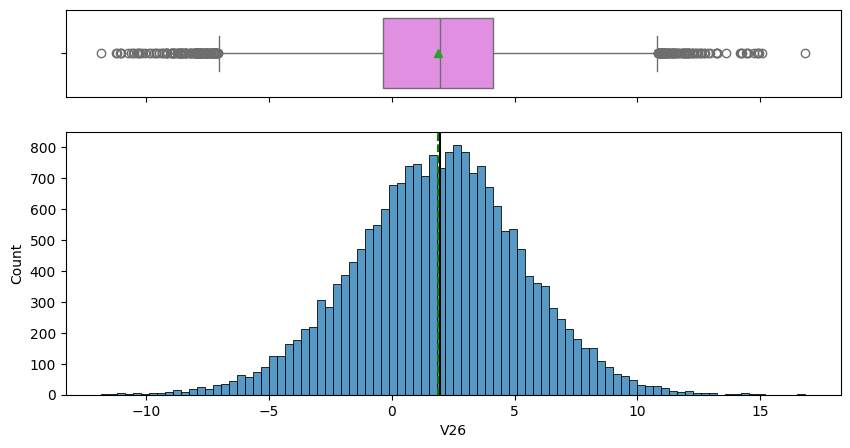

count   20000.000
mean        1.874
std         3.435
min       -11.834
25%        -0.338
50%         1.951
75%         4.130
max        16.836
Name: V26, dtype: float64
***********************


training data :  Boxplot and histogram for feature  V27


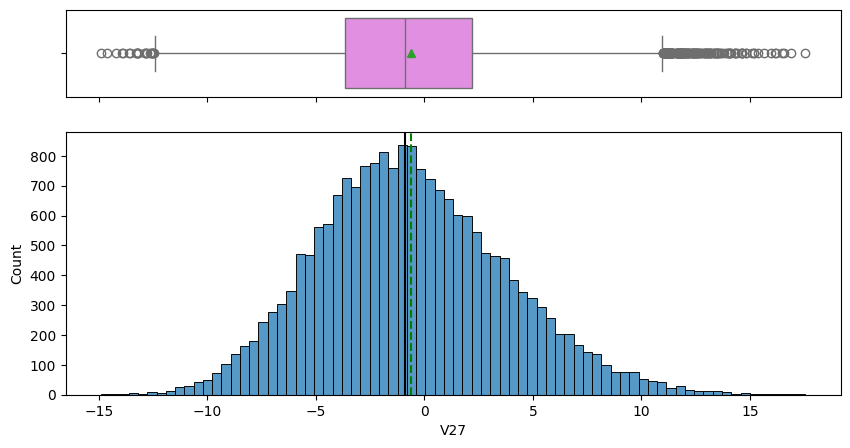

count   20000.000
mean       -0.612
std         4.369
min       -14.905
25%        -3.652
50%        -0.885
75%         2.189
max        17.560
Name: V27, dtype: float64
***********************


training data :  Boxplot and histogram for feature  V28


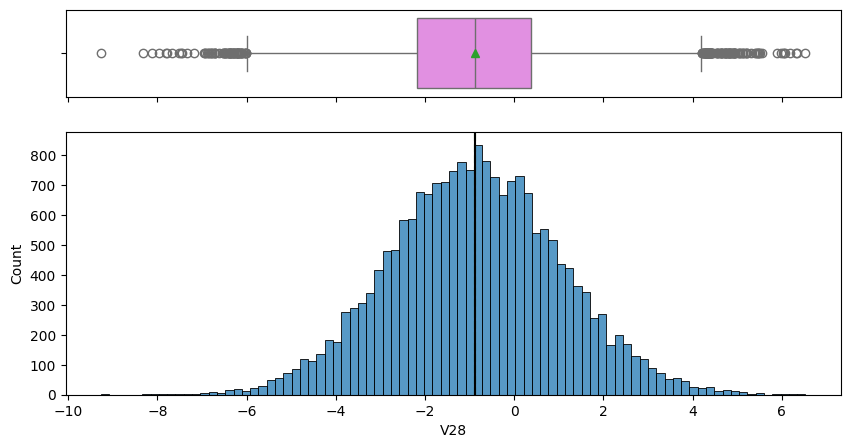

count   20000.000
mean       -0.883
std         1.918
min        -9.269
25%        -2.171
50%        -0.891
75%         0.376
max         6.528
Name: V28, dtype: float64
***********************


training data :  Boxplot and histogram for feature  V29


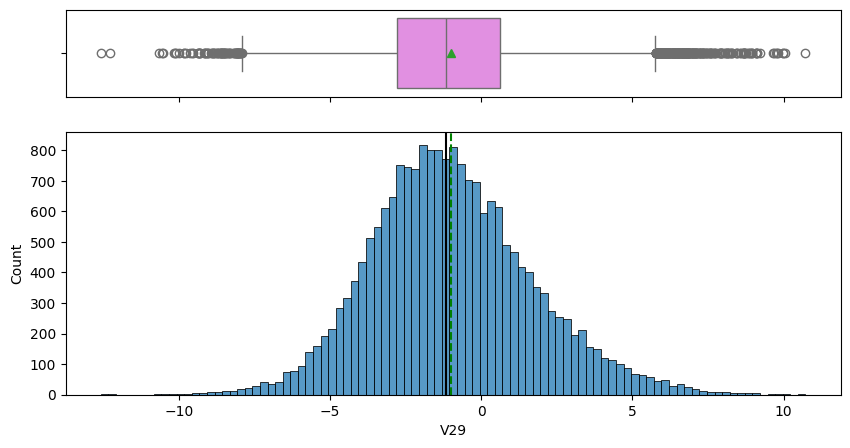

count   20000.000
mean       -0.986
std         2.684
min       -12.579
25%        -2.787
50%        -1.176
75%         0.630
max        10.722
Name: V29, dtype: float64
***********************


training data :  Boxplot and histogram for feature  V30


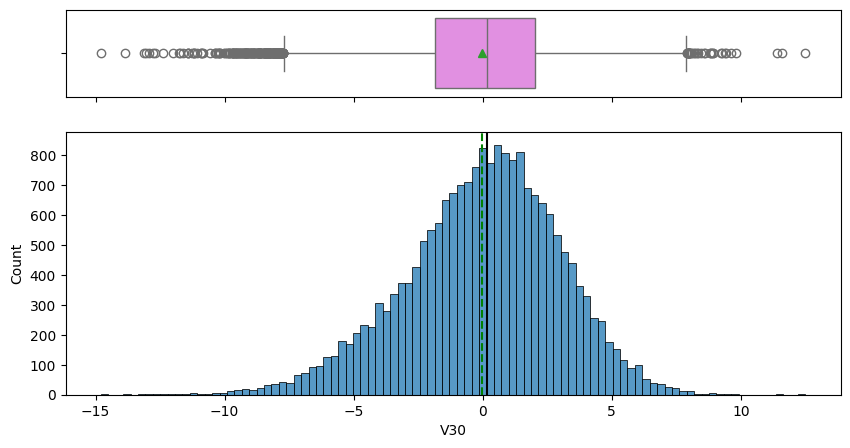

count   20000.000
mean       -0.016
std         3.005
min       -14.796
25%        -1.867
50%         0.184
75%         2.036
max        12.506
Name: V30, dtype: float64
***********************


training data :  Boxplot and histogram for feature  V31


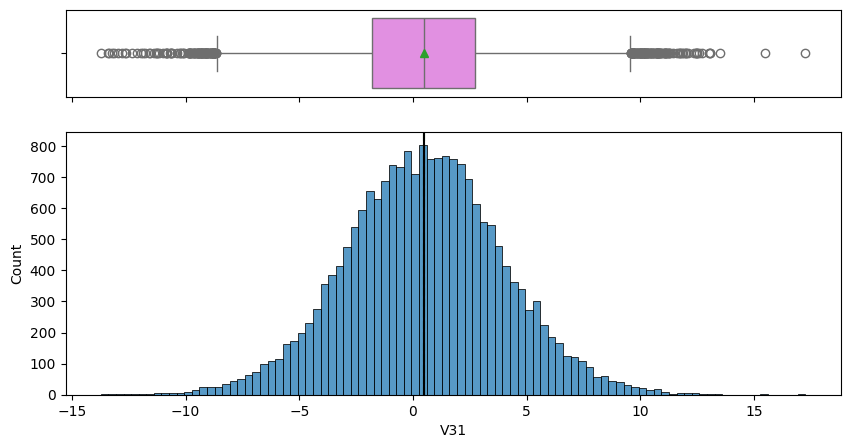

count   20000.000
mean        0.487
std         3.461
min       -13.723
25%        -1.818
50%         0.490
75%         2.731
max        17.255
Name: V31, dtype: float64
***********************


training data :  Boxplot and histogram for feature  V32


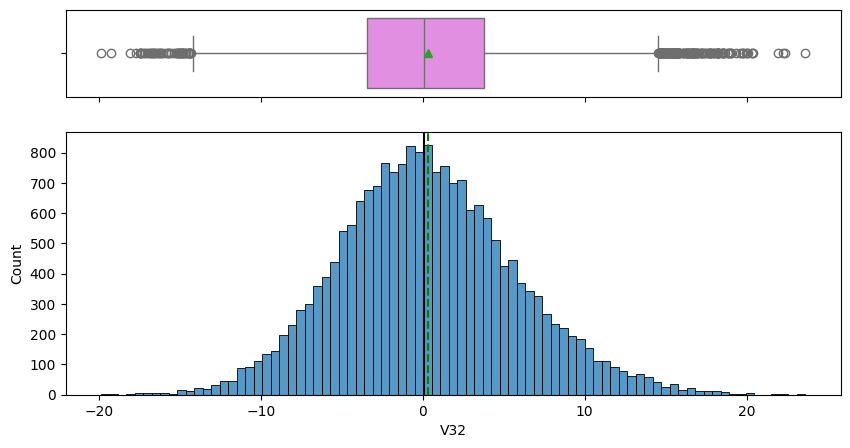

count   20000.000
mean        0.304
std         5.500
min       -19.877
25%        -3.420
50%         0.052
75%         3.762
max        23.633
Name: V32, dtype: float64
***********************


training data :  Boxplot and histogram for feature  V33


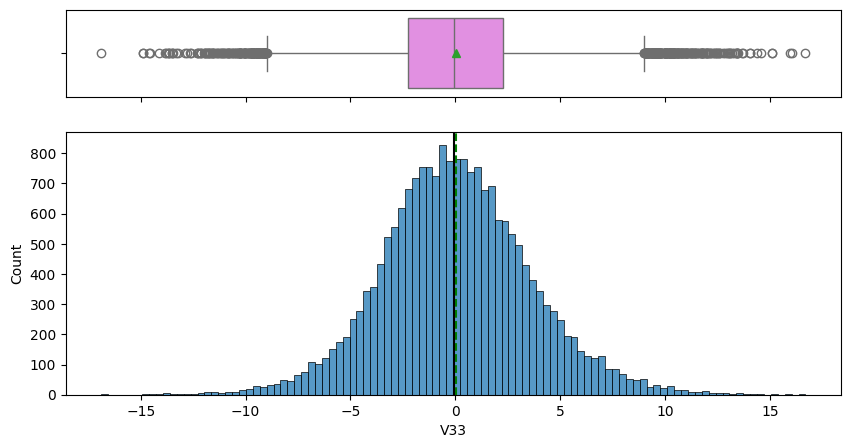

count   20000.000
mean        0.050
std         3.575
min       -16.898
25%        -2.243
50%        -0.066
75%         2.255
max        16.692
Name: V33, dtype: float64
***********************


training data :  Boxplot and histogram for feature  V34


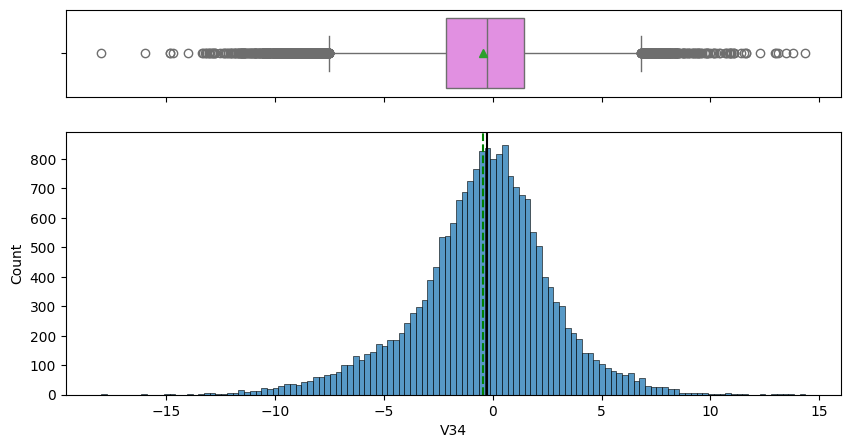

count   20000.000
mean       -0.463
std         3.184
min       -17.985
25%        -2.137
50%        -0.255
75%         1.437
max        14.358
Name: V34, dtype: float64
***********************


training data :  Boxplot and histogram for feature  V35


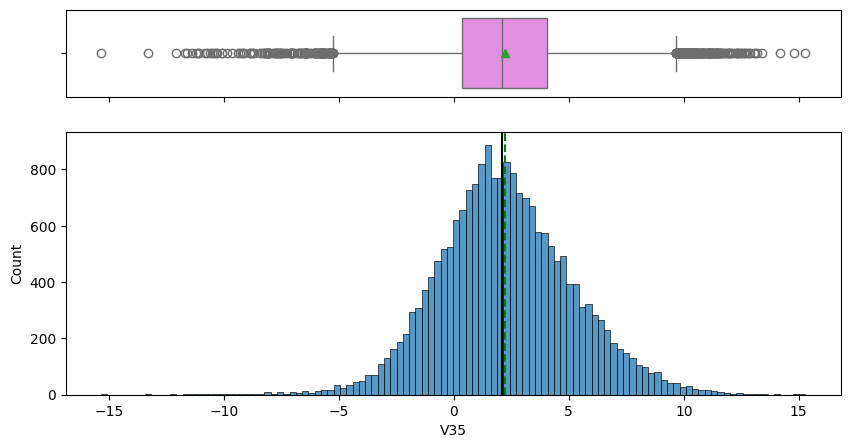

count   20000.000
mean        2.230
std         2.937
min       -15.350
25%         0.336
50%         2.099
75%         4.064
max        15.291
Name: V35, dtype: float64
***********************


training data :  Boxplot and histogram for feature  V36


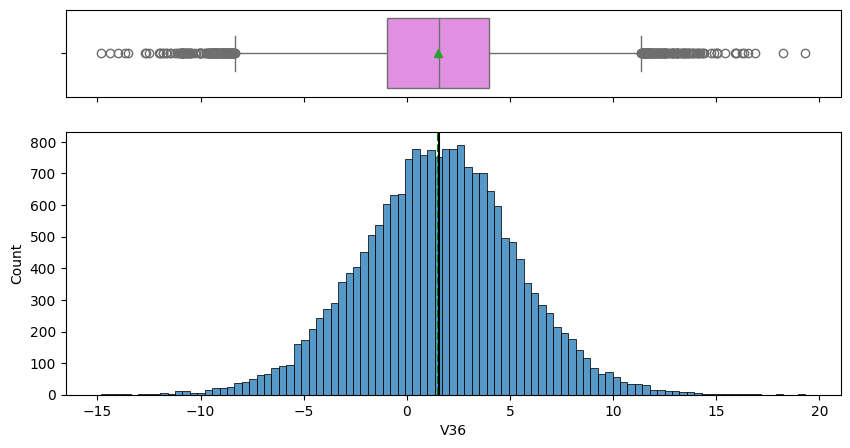

count   20000.000
mean        1.515
std         3.801
min       -14.833
25%        -0.944
50%         1.567
75%         3.984
max        19.330
Name: V36, dtype: float64
***********************


training data :  Boxplot and histogram for feature  V37


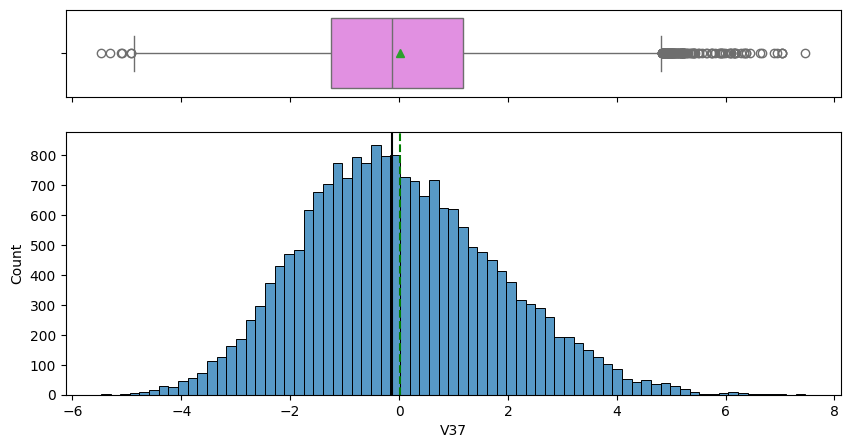

count   20000.000
mean        0.011
std         1.788
min        -5.478
25%        -1.256
50%        -0.128
75%         1.176
max         7.467
Name: V37, dtype: float64
***********************


training data :  Boxplot and histogram for feature  V38


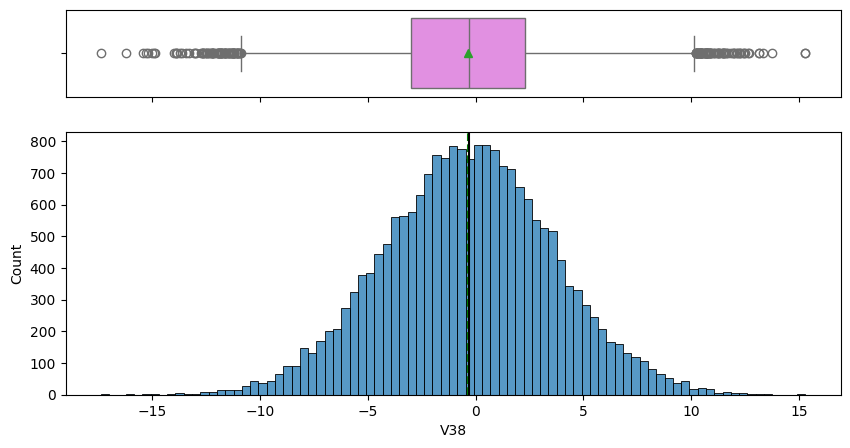

count   20000.000
mean       -0.344
std         3.948
min       -17.375
25%        -2.988
50%        -0.317
75%         2.279
max        15.290
Name: V38, dtype: float64
***********************


training data :  Boxplot and histogram for feature  V39


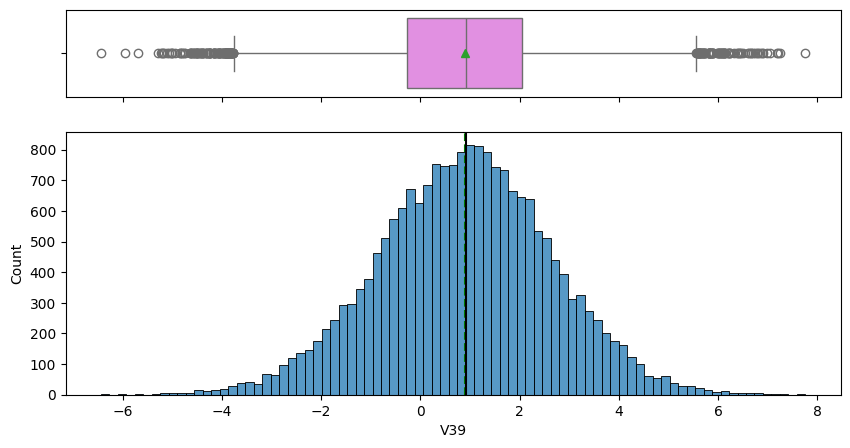

count   20000.000
mean        0.891
std         1.753
min        -6.439
25%        -0.272
50%         0.919
75%         2.058
max         7.760
Name: V39, dtype: float64
***********************


training data :  Boxplot and histogram for feature  V40


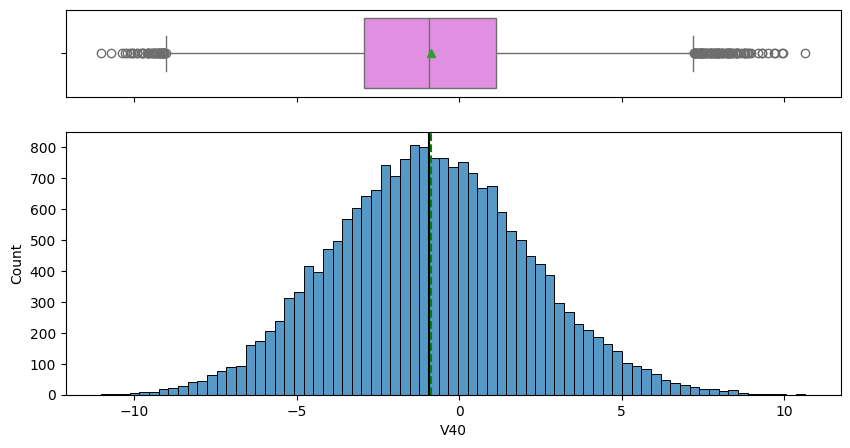

count   20000.000
mean       -0.876
std         3.012
min       -11.024
25%        -2.940
50%        -0.921
75%         1.120
max        10.654
Name: V40, dtype: float64
***********************


training data :  Boxplot and histogram for feature  Target


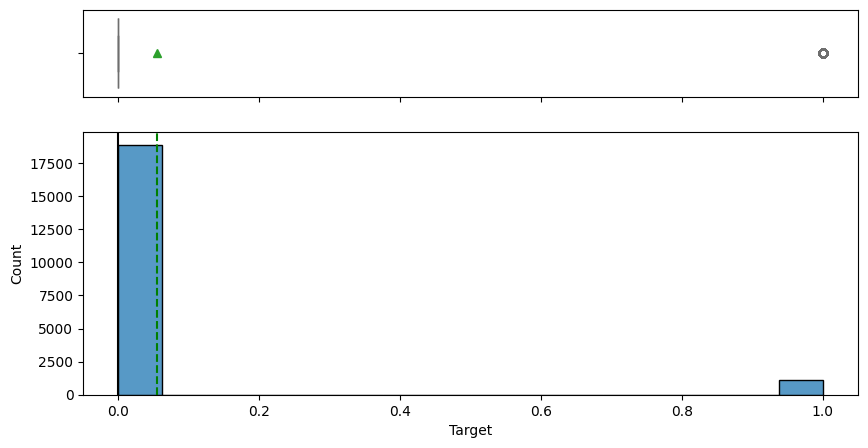

count   20000.000
mean        0.056
std         0.229
min         0.000
25%         0.000
50%         0.000
75%         0.000
max         1.000
Name: Target, dtype: float64
***********************




In [16]:
#C15
# a edetail for each feature in training data
for feature in df.columns:
    histogram_boxplot( df, feature, figsize=(10, 5), kde=False, bins=None, freetext="training data : ")

#### No EDA on test data.

 Test is used solely to score the final chosen model.

Looking at distributions, outliers, correlations, or class balance on Test before you lock the model lets information from the hold-out leak into your decisions (which features look useful, how to impute, whether to treat outliers, etc.). That makes the eventual Test score optimistic and no longer an honest estimate of how the model will perform on truly new data.


####Univariate EDA
1. V1–V40 are roughly unimodal and symmetric around a mean near zero (not formally tested as normal).
2. Positive and negative outliers are visible on all V1–V40.
3. Scales are broadly comparable (most values lie between roughly –20 and +20).
4. Outliers are left untreated. The FAQ states that negative (and extreme) values are legitimate ciphered sensor readings and contain information the model may need.
5. Target is binary: 0 = no failure, 1 = failure.  
   On Train the failure rate is approximately 5.55 % (mean ≈ 0.056).

## Data Pre-processing

In [17]:
#C15
#Split data

X = df.drop(["Target"], axis=1)
y = df["Target"]

In [18]:
#C16
#  Splitting data into training and validation sets:
X_train, X_val, y_train, y_val = train_test_split( X, y, test_size=0.30, random_state=1, stratify=y)

print(X_train.shape, X_val.shape)

(14000, 40) (6000, 40)


In [19]:
#C17
print(y_train.value_counts())
# y_train has 13,223 non-failures and 777 failures
#  (exactly 70 % of the original 20,000 rows, failure rate still ≈ 5.55 %).

Target
0    13223
1      777
Name: count, dtype: int64


In [20]:
#C18
print(y_val.value_counts())

Target
0    5667
1     333
Name: count, dtype: int64


####Data Pre-Processing
1. After the stratified split there are 14,000 rows in the training portion.
2. There are 6,000 rows in the validation portion.
3. Stratify preserved the original class balance: approximately 94.45 % no-failure (0) and 5.55 % failure (1) in both the training and validation portions.

## Missing value imputation




In [21]:
#C19
#  impute missing values in "V1" and "V2" columns.
imputer = SimpleImputer(strategy="median")
X_train = pd.DataFrame(imputer.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_val = pd.DataFrame(imputer.transform(X_val), columns=X_val.columns, index=X_val.index)

The nature of predictions made by the classification model will translate as follows:

- True positives (TP) are failures correctly predicted by the model.
- False negatives (FN) are real failures in a generator where there is no detection by model.
- False positives (FP) are failure detections in a generator where there is no failure.

**Which metric to optimize?**

* We need to choose the metric which will ensure that the maximum number of generator failures are predicted correctly by the model.
* We would want Recall to be maximized as greater the Recall, the higher the chances of minimizing false negatives.
* We want to minimize false negatives because if a model predicts that a machine will have no failure when there will be a failure, it will increase the maintenance cost.

## Model evaluation criterion
### 3 types of cost are associated with the provided problem
1. Replacement cost - False Negatives - Predicting no failure, while there will be a failure
2. Inspection cost - False Positives - Predicting failure, while there is no failure
3. Repair cost - True Positives - Predicting failure correctly

### How to reduce the overall cost?
* We need to create a customized metric, that can help to bring down the overall cost
* The cost associated with any model = (TPX15000) + (FPX5000) + (FNX40000)
* And the minimum possible cost will be when, the model will be able to identify all failures, in that case, the cost will be (TP + FN)X15000
* So, we will try to maximize `Minimum cost/Cost associated with model`

## Model Building

###define a function to output different metrics (including recall) on the train and test set

In [22]:
#C20
#  defining a function to compute different metrics to check performance of a classification model built using sklearn
def model_performance_classification_sklearn(model, predictors, target):
    """
    Function to compute different metrics to check classification model performance

    model: classifier
    predictors: independent variables
    target: dependent variable
    """

    TP = confusion_matrix(target, model.predict(predictors))[1, 1]
    FP = confusion_matrix(target, model.predict(predictors))[0, 1]
    FN = confusion_matrix(target, model.predict(predictors))[1, 0]
    Cost = TP * 15 + FP * 5 + FN * 40  # maintenance cost by using model
    Min_Cost = (
        TP + FN
    ) * 15  # minimum possible maintenance cost = number of actual positives
    Percent = (
        Min_Cost / Cost
    )  # ratio of minimum possible maintenance cost and maintenance cost by model

    # predicting using the independent variables
    pred = model.predict(predictors)

    acc = accuracy_score(target, pred)  # to compute Accuracy
    recall = recall_score(target, pred)  # to compute Recall
    precision = precision_score(target, pred)  # to compute Precision
    f1 = f1_score(target, pred)  # to compute F1-score

    # creating a dataframe of metrics
    df_perf = pd.DataFrame(
        {
            "Accuracy": acc,
            "Recall": recall,
            "Precision": precision,
            "F1": f1,
            "Minimum_Vs_Model_cost": Percent,
        },
        index=[0],
    )

    return df_perf

###define a function to show confusion matrix so that we do not have to use the same code repetitively while evaluating models

In [23]:
#C21
def confusion_matrix_sklearn(model, predictors, target):
    """
    To plot the confusion_matrix with percentages

    model: classifier
    predictors: independent variables
    target: dependent variable
    """
    y_pred = model.predict(predictors)
    cm = confusion_matrix(target, y_pred)
    labels = np.asarray(
        [
            ["{0:0.0f}".format(item) + "\n{0:.2%}".format(item / cm.flatten().sum())]
            for item in cm.flatten()
        ]
    ).reshape(2, 2)

    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=labels, fmt="")
    plt.ylabel("True label")
    plt.xlabel("Predicted label")

###Defining scorer to be used for cross-validation and hyperparameter tuning

- We want to reduce false negatives and will try to maximize "Recall".
- To maximize Recall, we can use Recall as a **scorer** in cross-validation and hyperparameter tuning.

In [24]:
#C22
#  defining metric to be used for optimization and with cross-validation
def Minimum_Vs_Model_cost(y_train, y_pred):
    """
    Ratio of theoretical minimum maintenance cost to the cost produced by the model.
    Minimum cost = (TP + FN) * 15  (all failures caught and repaired, no false positives).
    Model cost   = TP * 15 + FP * 5 + FN * 40.
    Higher ratio = lower relative maintenance cost = better model.
    """
    TP = confusion_matrix(y_train, y_pred)[1, 1]
    FP = confusion_matrix(y_train, y_pred)[0, 1]
    FN = confusion_matrix(y_train, y_pred)[1, 0]
    return ((TP + FN) * 15) / (TP * 15 + FP * 5 + FN * 40)


# A value of .80 here, will represent that the minimum maintenance cost is 80% of the maintenance cost associated with the model.
# Since minimum maintenance cost is constant for any data, when minimum cost will become 100% of maintenance cost associated with the model
# Model will have give the least possible maintenance cost.


# Type of scoring used to compare parameter combinations
scorer = metrics.make_scorer(Minimum_Vs_Model_cost, greater_is_better=True)

# Higher the values, the lower the maintenance cost

### Model Building with training data

In [25]:
#C22
models = []  # Empty list to store all the models

# Appending models into the list

models.append(("Logistic Regression", LogisticRegression(solver="newton-cg", random_state=1)))
models.append(("dtree", DecisionTreeClassifier(random_state=1)))
models.append(("Random forest", RandomForestClassifier(random_state=1)))
models.append(("Bagging", BaggingClassifier(random_state=1)))
models.append(("Adaboost", AdaBoostClassifier(random_state=1)))
models.append(("GBM", GradientBoostingClassifier(random_state=1)))
models.append(("Xgboost", XGBClassifier(random_state=1, eval_metric="logloss")))

results = []  # Empty list to store all model's CV scores
names = []  # Empty list to store name of the models
score = []

# loop through all models to get the mean cross validated score

print("\n" "Cross-Validation Performance:" "\n")

for name, model in models:
    kfold = StratifiedKFold(
        n_splits=5, shuffle=True, random_state=1
    )  # Setting number of splits equal to 5
    cv_result = cross_val_score(
        estimator=model, X=X_train, y=y_train, scoring=scorer, cv=kfold
    )
    results.append(cv_result)
    names.append(name)
    print("{}: {}".format(name, cv_result.mean()))


Cross-Validation Performance:

Logistic Regression: 0.5316984986583597
dtree: 0.6272059730009276
Random forest: 0.6807632984487395
Bagging: 0.6660391614500791
Adaboost: 0.5418274325204366
GBM: 0.6761183106181037
Xgboost: 0.7475218113467855


In [26]:
#C23
print("\n" "Training Performance:" "\n")

for name, model in models:
    model.fit(X_train, y_train)
    scores = Minimum_Vs_Model_cost(y_train, model.predict(X_train))
    print("{}: {}".format(name, scores))

# The perfect or near-perfect scores on the training data for the tree-based models are a classic over-fit signal;


Training Performance:

Logistic Regression: 0.5314637482900136
dtree: 1.0
Random forest: 0.9978595890410958
Bagging: 0.9301675977653632
Adaboost: 0.5627716079188798
GBM: 0.76905311778291
Xgboost: 1.0


- The cross-validation scores (customized metric) are similar to the validation performance scores. This indicates that the default algorithms on the original dataset are able to generalize well.
- There is a tendency for some models (decision tree, random forest, bagging and XGBoost) to overfit the training set, as their training performance score (customized metric) approaches 1.

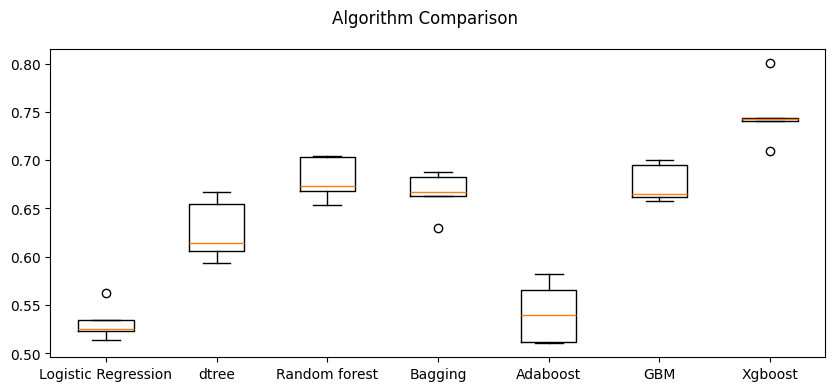

In [27]:
#C24
# Plotting boxplots for CV scores of all models defined above

fig = plt.figure(figsize=(10, 4))

fig.suptitle("Algorithm Comparison")
ax = fig.add_subplot(111)

plt.boxplot(results)
ax.set_xticklabels(names)

plt.show()

- XGBoost (median ≈ 0.74) and Random Forest (≈ 0.67) have the best average and median cross-validation scores. Bagging Classifier is close behind (≈ 0.67).
- Logistic Regression and Bagging each show one clear outlier in the boxplot.
- The spread of CV scores is small for Logistic Regression, XGBoost, and Bagging Classifier, indicating stable performance across folds.

### Model Building with Oversampled Training data


In [28]:
#C25
print("Before Oversampling, counts of label '1 (Failures)': {}".format(sum(y_train == 1)))
print("Before Oversampling, counts of label '0 (No failures)': {} \n".format(sum(y_train == 0)))

Before Oversampling, counts of label '1 (Failures)': 777
Before Oversampling, counts of label '0 (No failures)': 13223 



In [29]:
#C26
#  Synthetic Minority Over Sampling Technique
sm = SMOTE(sampling_strategy=1, k_neighbors=5, random_state=1)
X_train_over, y_train_over = sm.fit_resample(X_train, y_train)

In [30]:
#C27
print("After Oversampling, counts of label '1 (Failures)': {}".format(sum(y_train_over == 1)))
print( "After Oversampling, counts of label '0 (No failures)': {} \n".format( sum(y_train_over == 0) ))

After Oversampling, counts of label '1 (Failures)': 13223
After Oversampling, counts of label '0 (No failures)': 13223 



* To handle class imbalance in "Target" attribute the synthetic minority oversampling technique generates synthetic data points for minority class of importance (i.e, class "1" or No failures)
* After applying SMOTE, we have equal number of class "1" and calss "0" target outcomes
* 13,223 failures and No failures

In [31]:
#C28
models_over = []  # Empty list to store all the models

# Appending models into the list

models_over.append(("Logistic Regression", LogisticRegression(solver="newton-cg", random_state=1)))
models_over.append(("dtree", DecisionTreeClassifier(random_state=1)))
models_over.append(("Random forest", RandomForestClassifier(random_state=1)))
models_over.append(("Bagging", BaggingClassifier(random_state=1)))
models_over.append(("Adaboost", AdaBoostClassifier(random_state=1)))
models_over.append(("GBM", GradientBoostingClassifier(random_state=1)))
models_over.append(("Xgboost", XGBClassifier(random_state=1, eval_metric="logloss")))

results_over = []  # Empty list to store all model's CV scores
names_over = []  # Empty list to store name of the models
score_over = []

# loop through all models to get the mean cross validated score

print("\n" "Cross-Validation Performance:" "\n")

for name, model in models_over:
    kfold = StratifiedKFold(
        n_splits=5, shuffle=True, random_state=1
    )  # Setting number of splits equal to 5
    cv_result = cross_val_score(
        estimator=model, X=X_train_over, y=y_train_over, scoring=scorer, cv=kfold
    )
    results_over.append(cv_result)
    names_over.append(name)
    print("{}: {}".format(name, cv_result.mean()))


Cross-Validation Performance:

Logistic Regression: 0.8193345969360125
dtree: 0.9386129564423099
Random forest: 0.9711519462836454
Bagging: 0.9557133408484612
Adaboost: 0.8311147830442506
GBM: 0.8919788115984149
Xgboost: 0.9818384177227244


In [32]:
#C29
print("\n" "Training Performance:" "\n")

for name, model in models_over:
    model.fit(X_train_over, y_train_over)
    scores = Minimum_Vs_Model_cost(y_train_over, model.predict(X_train_over))
    print("{}: {}".format(name, scores))


Training Performance:

Logistic Regression: 0.8194381326172279
dtree: 1.0
Random forest: 1.0
Bagging: 0.9969590349334003
Adaboost: 0.8301732797589151
GBM: 0.8979356240662774
Xgboost: 1.0


In [33]:
#C30

print("\n" "Validation Performance:" "\n")

for name, model in models_over:
    model.fit(X_train_over, y_train_over)
    scores = Minimum_Vs_Model_cost(y_val, model.predict(X_val))
    print("{}: {}".format(name, scores))


Validation Performance:

Logistic Regression: 0.5015060240963856
dtree: 0.627906976744186
Random forest: 0.7884767166535123
Bagging: 0.7324046920821115
Adaboost: 0.5444141689373297
GBM: 0.7140814867762688
Xgboost: 0.7859952793076318


- The cross-validation scores on the oversampled data are much higher than the validation scores.
- This indicates that the default algorithms trained on the oversampled data are not generalizing as well as they did on the original data.
- The gap (CV ≈ training score ≫ validation score) suggests the models are overfitting noise in the balanced training set.
- That gap is a concern if these models are taken to production without further tuning or regularization.

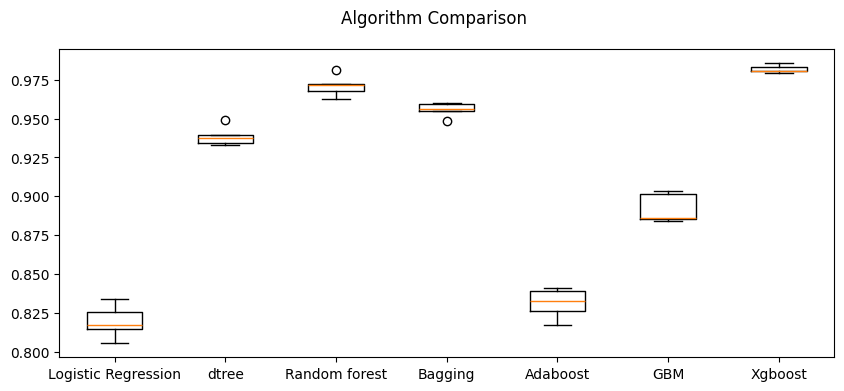

In [34]:
#C31

# Plotting boxplots for CV scores of all models defined above

fig = plt.figure(figsize=(10, 4))

fig.suptitle("Algorithm Comparison")
ax = fig.add_subplot(111)

plt.boxplot(results_over)
ax.set_xticklabels(names)

plt.show()

The average, median training cross validation scores on oversampled dataset have increased to match training performance scores across algorithms.
This indicates potential overfitting / noise in  training datasets.

### Model Building with Undersampled data

In [35]:
#C32 Random undersampler for under sampling the data

rus = RandomUnderSampler(random_state=1, sampling_strategy=1)
X_train_un, y_train_un = rus.fit_resample(X_train, y_train)

In [36]:
#C33
print("After Undersampling, counts of label '1 (Failures)': {}".format( sum(y_train_un == 1)))
print("After Undersampling, counts of label '0 (No failures)': {} \n".format(sum(y_train_un == 0)))

After Undersampling, counts of label '1 (Failures)': 777
After Undersampling, counts of label '0 (No failures)': 777 



After random undersamplin have equag wel number of class "1" and class "0" (777)

Note: a technique to handle class imbalance in "Target" attribute is random undersampling
only random samples from the majority class are chosen for model building.
While this helps in dealing with models potentially overfitting,
it can often lead to poor performing models due to "loss of information"
from not considering all datapoints available.

In [37]:
#C34
models_un = []  # Empty list to store all the models

# Appending models into the list

models_un.append(("Logistic Regression", LogisticRegression(solver="newton-cg", random_state=1)))
models_un.append(("dtree", DecisionTreeClassifier(random_state=1)))
models_un.append(("Random forest", RandomForestClassifier(random_state=1)))
models_un.append(("Bagging", BaggingClassifier(random_state=1)))
models_un.append(("Adaboost", AdaBoostClassifier(random_state=1)))
models_un.append(("GBM", GradientBoostingClassifier(random_state=1)))
models_un.append(("Xgboost", XGBClassifier(random_state=1, eval_metric="logloss")))

results_un = []  # Empty list to store all model's CV scores
names_un = []  # Empty list to store name of the models
score_un = []

# loop through all models to get the mean cross validated score

print("\n" "Cross-Validation Performance:" "\n")

for name, model in models_un:
    kfold = StratifiedKFold(
        n_splits=5, shuffle=True, random_state=1
    )  # Setting number of splits equal to 5
    cv_result = cross_val_score(
        estimator=model, X=X_train_un, y=y_train_un, scoring=scorer, cv=kfold
    )
    results_un.append(cv_result)
    names_un.append(name)
    print("{}: {}".format(name, cv_result.mean()))


Cross-Validation Performance:

Logistic Regression: 0.7976859395663183
dtree: 0.7835207678693784
Random forest: 0.8520819199404063
Bagging: 0.8191168871899597
Adaboost: 0.7934304522891094
GBM: 0.834807164772231
Xgboost: 0.8475779141640956


In [38]:
#C35
print("\n" "Training Performance:" "\n")

for name, model in models_un:
    model.fit(X_train_un, y_train_un)
    scores = Minimum_Vs_Model_cost(y_train_un, model.predict(X_train_un))
    print("{}: {}".format(name, scores))


Training Performance:

Logistic Regression: 0.7963785445848992
dtree: 1.0
Random forest: 1.0
Bagging: 0.9765395894428153
Adaboost: 0.8176078568923185
GBM: 0.920252664824319
Xgboost: 1.0


In [39]:
#C36
print("\n" "Validation Performance:" "\n")

for name, model in models_un:
    model.fit(X_train_un, y_train_un)
    scores = Minimum_Vs_Model_cost(y_val, model.predict(X_val))
    print("{}: {}".format(name, scores))


Validation Performance:

Logistic Regression: 0.47684964200477326
dtree: 0.4495949594959496
Random forest: 0.6466019417475728
Bagging: 0.6125076640098099
Adaboost: 0.4889867841409692
GBM: 0.6239850093691443
Xgboost: 0.6800544588155207


The validation scores are lower than those obtained from the original data.  
This is consistent with the loss of information from undersampling: the models over-fit the small balanced set and under-fit the broader patterns present in the full data.  
Taking these models to production without further work would be a concern.

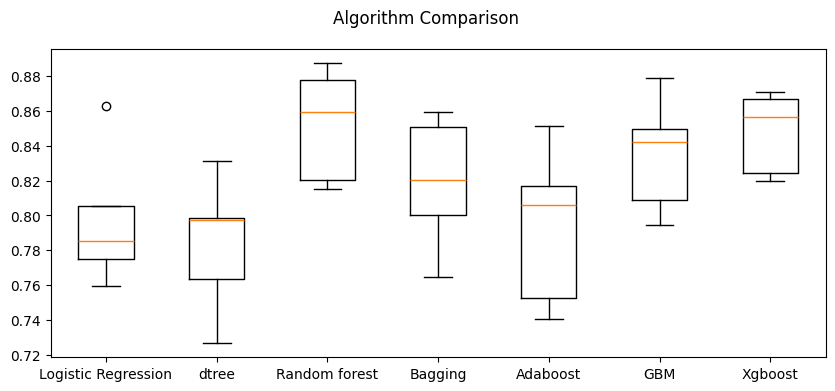

In [40]:
# Plotting boxplots for CV scores of all models defined above
#C37

fig = plt.figure(figsize=(10, 4))

fig.suptitle("Algorithm Comparison")
ax = fig.add_subplot(111)

plt.boxplot(results_un)
ax.set_xticklabels(names)

plt.show()

The algorithms produce higher cross-validation scores on the undersampled data than they did on the original data.  
However, those gains do not carry over to the validation set, indicating limited generalizability.

Models built on the original data generalized better (CV scores close to validation scores) than those built on oversampled or undersampled data.  
Across the experiments the strongest and most consistent performers were Random Forest, XGBoost, and Gradient Boosting.  
These three will be taken forward for hyper-parameter tuning.

## HyperparameterTuning

### Sample Parameter Grids

**Hyperparameter tuning can take a long time to run, so to avoid that time complexity - you can use the following grids, wherever required.**

- For Gradient Boosting:

param_grid = {
    "n_estimators": np.arange(100,150,25),
    "learning_rate": [0.2, 0.05, 1],
    "subsample":[0.5,0.7],
    "max_features":[0.5,0.7]
}

- For Adaboost:

param_grid = {
    "n_estimators": [100, 150, 200],
    "learning_rate": [0.2, 0.05],
    "base_estimator": [DecisionTreeClassifier(max_depth=1, random_state=1), DecisionTreeClassifier(max_depth=2, random_state=1), DecisionTreeClassifier(max_depth=3, random_state=1),
    ]
}

- For Bagging Classifier:

param_grid = {
    'max_samples': [0.8,0.9,1],
    'max_features': [0.7,0.8,0.9],
    'n_estimators' : [30,50,70],
}

- For Random Forest:

param_grid = {
    "n_estimators": [200,250,300],
    "min_samples_leaf": np.arange(1, 4),
    "max_features": [np.arange(0.3, 0.6, 0.1),'sqrt'],
    "max_samples": np.arange(0.4, 0.7, 0.1)
}

- For Decision Trees:

param_grid = {
    'max_depth': np.arange(2,6),
    'min_samples_leaf': [1, 4, 7],
    'max_leaf_nodes' : [10, 15],
    'min_impurity_decrease': [0.0001,0.001]
}

- For Logistic Regression:

param_grid = {'C': np.arange(0.1,1.1,0.1)}

- For XGBoost:

param_grid={
    'n_estimators': [150, 200, 250],
    'scale_pos_weight': [5,10],
    'learning_rate': [0.1,0.2],
    'gamma': [0,3,5],
    'subsample': [0.8,0.9]
}

###XGBoost Hyperparameter Tuning

In [41]:
#C38
#  defining model - XGBoost Hyperparameter Tuning

model = XGBClassifier(random_state=1, eval_metric="logloss")

# Parameter grid to pass in RandomizedSearchCV
param_grid = {
    "n_estimators": np.arange(150, 300, 50),
    "scale_pos_weight": [5, 10],
    "learning_rate": [0.1, 0.2],
    "gamma": [0, 3, 5],
    "subsample": [0.8, 0.9],
}

# Type of scoring used to compare parameter combinations
scorer = metrics.make_scorer(Minimum_Vs_Model_cost, greater_is_better=True)

# Calling RandomizedSearchCV
randomized_cv = RandomizedSearchCV(
    estimator=model,
    param_distributions=param_grid,
    n_iter=20,
    scoring=scorer,
    cv=3,
    random_state=1,
    n_jobs=-1,
)

# Fitting parameters in RandomizedSearchCV
randomized_cv.fit(X_train, y_train)

print(
    "Best parameters are {} with CV score={}:".format(
        randomized_cv.best_params_, randomized_cv.best_score_
    )
)

Best parameters are {'subsample': 0.8, 'scale_pos_weight': 10, 'n_estimators': np.int64(250), 'learning_rate': 0.1, 'gamma': 3} with CV score=0.7931759520045055:


In [43]:
# building model with best parameters
#C39
xgb_tuned = XGBClassifier(
    subsample=0.8,
    scale_pos_weight=10,
    n_estimators=250,
    learning_rate=0.1,
    gamma=3,
    random_state=1,
    eval_metric="logloss",
)

# Fit the model on training data
print(xgb_tuned.fit(X_train, y_train))

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=3,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=250, n_jobs=None,
              num_parallel_tree=None, ...)


In [45]:
# Calculating different metrics on training set
#C40
xgboost_random_train = model_performance_classification_sklearn(xgb_tuned, X_train, y_train)
print("Training performance:")
print(xgboost_random_train)

Training performance:
   Accuracy  Recall  Precision    F1  Minimum_Vs_Model_cost
0     0.999   1.000      0.980 0.990                  0.993


In [46]:
# Calculating different metrics on validation set
#C41
xgboost_random_val = model_performance_classification_sklearn(xgb_tuned, X_val, y_val)
print("Validation performance:")
print(xgboost_random_val)

Validation performance:
   Accuracy  Recall  Precision    F1  Minimum_Vs_Model_cost
0     0.990   0.859      0.947 0.901                  0.799


- The best hyperparameters found by RandomizedSearchCV for XGBoost were: subsample 0.8, scale_pos_weight 10, n_estimators 250, learning_rate 0.1, gamma 3.
- The cross-validation score with these parameters (≈ 0.79) is close to the validation cost-ratio (0.799), indicating the model generalizes.
- A gap remains between the training cost-ratio (0.993) and the validation score, so some overfitting is still present.

###Random Forest Hyperparameter Tuning

In [47]:
# defining model - Random Forest Hyperparameter Tuning
#C41
model2 = RandomForestClassifier(random_state=1, oob_score=True, bootstrap=True)

param_grid2 = {
    "n_estimators": [150, 250],
    "min_samples_leaf": np.arange(1, 3),
    "max_features": ["sqrt", "log2"],
    "max_samples": np.arange(0.2, 0.6, 0.1),
}

# Type of scoring used to compare parameter combinations
scorer = metrics.make_scorer(Minimum_Vs_Model_cost, greater_is_better=True)

# Calling RandomizedSearchCV
randomized_cv2 = RandomizedSearchCV(
    estimator=model2,
    param_distributions=param_grid2,
    n_iter=50,
    scoring=scorer,
    cv=5,
    random_state=1,
    n_jobs=-1,
)

# Fitting parameters in RandomizedSearchCV
randomized_cv2.fit(X_train, y_train)
print(
    "Best parameters are {} with CV score={}:".format(
        randomized_cv2.best_params_, randomized_cv2.best_score_
    )
)

Best parameters are {'n_estimators': 250, 'min_samples_leaf': np.int64(1), 'max_samples': np.float64(0.5000000000000001), 'max_features': 'sqrt'} with CV score=0.6557584099550935:


In [48]:
#C42
rf_tuned = RandomForestClassifier(
    n_estimators=250,
    min_samples_leaf=1,
    max_samples=0.5000000000000001,
    max_features="sqrt",
    random_state=1,
)

# Fit the model on training data
print(rf_tuned.fit(X_train, y_train))

RandomForestClassifier(max_samples=0.5000000000000001, n_estimators=250,
                       random_state=1)

In [50]:
# Calculating different metrics on training set
#C43
rf_random_train = model_performance_classification_sklearn(rf_tuned, X_train, y_train)
print("Training performance:")
print(rf_random_train)

Training performance:
   Accuracy  Recall  Precision    F1  Minimum_Vs_Model_cost
0     0.993   0.866      1.000 0.928                  0.818


In [51]:
# Calculating different metrics on validation set
#C44
rf_random_val = model_performance_classification_sklearn(rf_tuned, X_val, y_val)
print("Validation performance:")
print(rf_random_val)

Validation performance:
   Accuracy  Recall  Precision    F1  Minimum_Vs_Model_cost
0     0.984   0.718      0.988 0.831                  0.679


- The best hyperparameters found by RandomizedSearchCV for Random Forest were: n_estimators 250, min_samples_leaf 1, max_features 'sqrt', max_samples 0.5.
- The 5-fold cross-validation cost-ratio with these parameters is 0.656, close to the validation cost-ratio of 0.679.
- This indicates the model generalizes at approximately 0.67.
- There is a modest gap between the training cost-ratio (0.818) and the validation score, smaller than the gap seen with the tuned XGBoost.

###Bagging Classifier Hyperparameter Tuning

In [52]:
# defining model - Bagging Classifier Hyperparameter Tuning
#C45
model3 = BaggingClassifier(random_state=1)

param_grid3 = {
    "max_samples": [0.8, 0.9],
    "max_features": [0.8, 0.9],
    "n_estimators": [40, 50],
}

# Type of scoring used to compare parameter combinations
scorer = metrics.make_scorer(Minimum_Vs_Model_cost, greater_is_better=True)

# Calling RandomizedSearchCV
randomized_cv3 = RandomizedSearchCV(
    estimator=model3,
    param_distributions=param_grid3,
    n_iter=50,
    scoring=scorer,
    cv=5,
    random_state=1,
    n_jobs=-1,
)

# Fitting parameters in RandomizedSearchCV
randomized_cv3.fit(X_train, y_train)
print(
    "Best parameters are {} with CV score={}:".format(
        randomized_cv3.best_params_, randomized_cv3.best_score_
    )
)

Best parameters are {'n_estimators': 50, 'max_samples': 0.8, 'max_features': 0.9} with CV score=0.6812367143149652:


In [53]:
# building model with best parameters
#C46
bagging_tuned = BaggingClassifier(n_estimators=50, max_samples=0.8, max_features=0.8, random_state=1,)

# Fit the model on training data
print(bagging_tuned.fit(X_train, y_train))

BaggingClassifier(max_features=0.8, max_samples=0.8, n_estimators=50,
                  random_state=1)


In [54]:
# Calculating different metrics on train set
#C47
bagging_random_train = model_performance_classification_sklearn(bagging_tuned, X_train, y_train)
print("Training performance:")
print(bagging_random_train)

Training performance:
   Accuracy  Recall  Precision    F1  Minimum_Vs_Model_cost
0     0.999   0.981      1.000 0.990                  0.969


In [55]:
# Calculating different metrics on validation set
#C48
bagging_random_val = model_performance_classification_sklearn(bagging_tuned, X_val, y_val)
print("Validation performance:")
print(bagging_random_val)

Validation performance:
   Accuracy  Recall  Precision    F1  Minimum_Vs_Model_cost
0     0.985   0.751      0.969 0.846                  0.703


- The best hyperparameters found by RandomizedSearchCV for the Bagging Classifier were: n_estimators 50, max_samples 0.8, max_features 0.9.
- The 5-fold cross-validation cost-ratio with these parameters is 0.681, close to the validation cost-ratio of 0.703.
- This indicates the model generalizes at approximately 0.68–0.70.
- A gap remains between the training cost-ratio (0.969) and the validation score, showing some overfitting.

In [56]:
# defining model
#C49
Model = DecisionTreeClassifier(random_state=1)

# Parameter grid to pass in RandomSearchCV
param_grid = {'max_depth': np.arange(2,6),
              'min_samples_leaf': [1, 4, 7],
              'max_leaf_nodes' : [10,15],
              'min_impurity_decrease': [0.0001,0.001] }

#Calling RandomizedSearchCV
randomized_cv = RandomizedSearchCV(estimator=Model, param_distributions=param_grid, n_iter=10, n_jobs = -1, scoring=scorer, cv=5, random_state=1)

#Fitting parameters in RandomizedSearchCV
randomized_cv.fit(X_train,y_train)

print("Best parameters are {} with CV score={}:" .format(randomized_cv.best_params_,randomized_cv.best_score_))

Best parameters are {'min_samples_leaf': 7, 'min_impurity_decrease': 0.0001, 'max_leaf_nodes': 15, 'max_depth': np.int64(5)} with CV score=0.5638887565237448:


In [57]:
# defining model
#C50
Model = DecisionTreeClassifier(random_state=1)

# Parameter grid to pass in RandomSearchCV
param_grid = {'max_depth': np.arange(2,6),
              'min_samples_leaf': [1, 4, 7],
              'max_leaf_nodes' : [10,15],
              'min_impurity_decrease': [0.0001,0.001] }

#Calling RandomizedSearchCV
randomized_cv = RandomizedSearchCV(estimator=Model, param_distributions=param_grid, n_iter=10, n_jobs = -1, scoring=scorer, cv=5, random_state=1)

#Fitting parameters in RandomizedSearchCV
randomized_cv.fit(X_train_over,y_train_over)

print("Best parameters are {} with CV score={}:" .format(randomized_cv.best_params_,randomized_cv.best_score_))

Best parameters are {'min_samples_leaf': 7, 'min_impurity_decrease': 0.0001, 'max_leaf_nodes': 15, 'max_depth': np.int64(5)} with CV score=0.830098879147896:


In [58]:
# defining model
#C51
Model = DecisionTreeClassifier(random_state=1)

# Parameter grid to pass in RandomSearchCV
param_grid = {'max_depth': np.arange(2,20),
              'min_samples_leaf': [1, 2, 5, 7],
              'max_leaf_nodes' : [5, 10,15],
              'min_impurity_decrease': [0.0001,0.001] }

#Calling RandomizedSearchCV
randomized_cv = RandomizedSearchCV(estimator=Model, param_distributions=param_grid, n_iter=10, n_jobs = -1, scoring=scorer, cv=5, random_state=1)

#Fitting parameters in RandomizedSearchCV
randomized_cv.fit(X_train_un,y_train_un)

print("Best parameters are {} with CV score={}:" .format(randomized_cv.best_params_,randomized_cv.best_score_))

Best parameters are {'min_samples_leaf': 1, 'min_impurity_decrease': 0.001, 'max_leaf_nodes': 15, 'max_depth': np.int64(11)} with CV score=0.7630569558826406:


## Model performance comparison and choosing the final model

In [59]:
# training performance comparison
#C52

models_train_comp_df = pd.concat([xgboost_random_train.T, rf_random_train.T, bagging_random_train.T,], axis=1,)
models_train_comp_df.columns = [
    "XGBoost Tuned with Random search",
    "Random forest Tuned with Random search",
    "Bagging Tuned with Random Search",
]
print("Training performance comparison:")
print(models_train_comp_df)

Training performance comparison:
                       XGBoost Tuned with Random search  \
Accuracy                                          0.999   
Recall                                            1.000   
Precision                                         0.980   
F1                                                0.990   
Minimum_Vs_Model_cost                             0.993   

                       Random forest Tuned with Random search  \
Accuracy                                                0.993   
Recall                                                  0.866   
Precision                                               1.000   
F1                                                      0.928   
Minimum_Vs_Model_cost                                   0.818   

                       Bagging Tuned with Random Search  
Accuracy                                          0.999  
Recall                                            0.981  
Precision                                      

In [60]:
# training performance comparison
#C53

models_val_comp_df = pd.concat( [xgboost_random_val.T, rf_random_val.T, bagging_random_val.T,], axis=1,)
models_val_comp_df.columns = [
    "XGBoost Tuned with Random search",
    "Random forest Tuned with Random search",
    "Bagging Tuned with Random Search",
]
print("Validation performance comparison:")
print(models_val_comp_df)

Validation performance comparison:
                       XGBoost Tuned with Random search  \
Accuracy                                          0.990   
Recall                                            0.859   
Precision                                         0.947   
F1                                                0.901   
Minimum_Vs_Model_cost                             0.799   

                       Random forest Tuned with Random search  \
Accuracy                                                0.984   
Recall                                                  0.718   
Precision                                               0.988   
F1                                                      0.831   
Minimum_Vs_Model_cost                                   0.679   

                       Bagging Tuned with Random Search  
Accuracy                                          0.985  
Recall                                            0.751  
Precision                                    

- The XGBoost model tuned with RandomizedSearchCV gives the highest Minimum_Vs_Model_cost on the validation set (0.799).
- Its training cost-ratio is higher (0.993), indicating some overfitting.
- The cross-validation score with the best parameters (≈ 0.79) is close to the validation score, supporting the choice.

 We choose 	XGBoost Tuned with Random search to see if it can generalize  on the testing dataset to give a likewise high performance score (Minimum_Vs_Model_cost) ~ 0.8

### Test set final performance

In [61]:
#C54
#  Loading the dataset
test = pd.read_csv("Test.csv")

In [62]:
#C55
X_test = test.drop(["Target"], axis=1)
y_test = test["Target"]

In [68]:
#C56
# print(y_test.value_counts)

<bound method IndexOpsMixin.value_counts of 0       0
1       0
2       0
3       0
4       0
5       0
6       0
7       0
8       0
9       0
10      0
11      0
12      0
13      0
14      0
15      0
16      0
17      0
18      0
19      0
20      0
21      0
22      0
23      0
24      0
25      0
26      0
27      0
28      0
29      0
30      0
31      0
32      0
33      0
34      0
35      0
36      0
37      0
38      0
39      0
40      0
41      0
42      0
43      0
44      0
45      0
46      0
47      0
48      0
49      0
50      0
51      0
52      0
53      0
54      0
55      0
56      0
57      0
58      0
59      0
60      0
61      0
62      0
63      0
64      0
65      0
66      0
67      0
68      0
69      0
70      0
71      0
72      0
73      0
74      1
75      0
76      0
77      0
78      0
79      0
80      0
81      0
82      0
83      0
84      0
85      0
86      0
87      0
88      0
89      0
90      0
91      0
92      0
93      0
94      0
95    

In [66]:
#C57
print(X_test.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 40 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   V1      4995 non-null   float64
 1   V2      4994 non-null   float64
 2   V3      5000 non-null   float64
 3   V4      5000 non-null   float64
 4   V5      5000 non-null   float64
 5   V6      5000 non-null   float64
 6   V7      5000 non-null   float64
 7   V8      5000 non-null   float64
 8   V9      5000 non-null   float64
 9   V10     5000 non-null   float64
 10  V11     5000 non-null   float64
 11  V12     5000 non-null   float64
 12  V13     5000 non-null   float64
 13  V14     5000 non-null   float64
 14  V15     5000 non-null   float64
 15  V16     5000 non-null   float64
 16  V17     5000 non-null   float64
 17  V18     5000 non-null   float64
 18  V19     5000 non-null   float64
 19  V20     5000 non-null   float64
 20  V21     5000 non-null   float64
 21  V22     5000 non-null   float64
 22  

There are 5 & 6 missing values for attributes "V1" and "V2"

In [72]:
#C58
# imputer was fit earlier on X_train
X_test = imputer.transform(X_test)

In [70]:
print("\n" "Test Performance:" "\n")
#C59
final_model = XGBClassifier(
    subsample=0.9,
    scale_pos_weight=10,
    n_estimators=250,
    learning_rate=0.1,
    gamma=3,
    random_state=1,
    eval_metric="logloss",
)
name = "XGboost_tuned"

final_model.fit(X_train, y_train)
final_scores = Minimum_Vs_Model_cost(y_test, final_model.predict(X_test))
print("{}: {}".format(name, final_scores))


Test Performance:

XGboost_tuned: 0.7663043478260869


In [74]:
#C60
xgboost_test = model_performance_classification_sklearn(final_model, X_test, y_test)
print (xgboost_test)

   Accuracy  Recall  Precision    F1  Minimum_Vs_Model_cost
0     0.987   0.830      0.929 0.876                  0.766


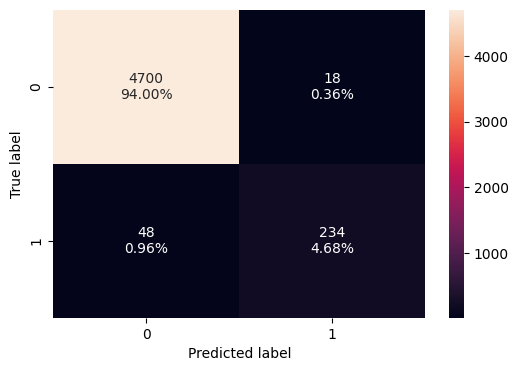

In [75]:
#C61
#  creating confusion matrix
confusion_matrix_sklearn(final_model, X_test, y_test)

The XGBoost tuned model generalizes well on the Test data with a Minimum_Vs_Model_cost of 0.766.
This means the model’s maintenance cost is approximately 1.31 times the theoretical minimum possible cost.

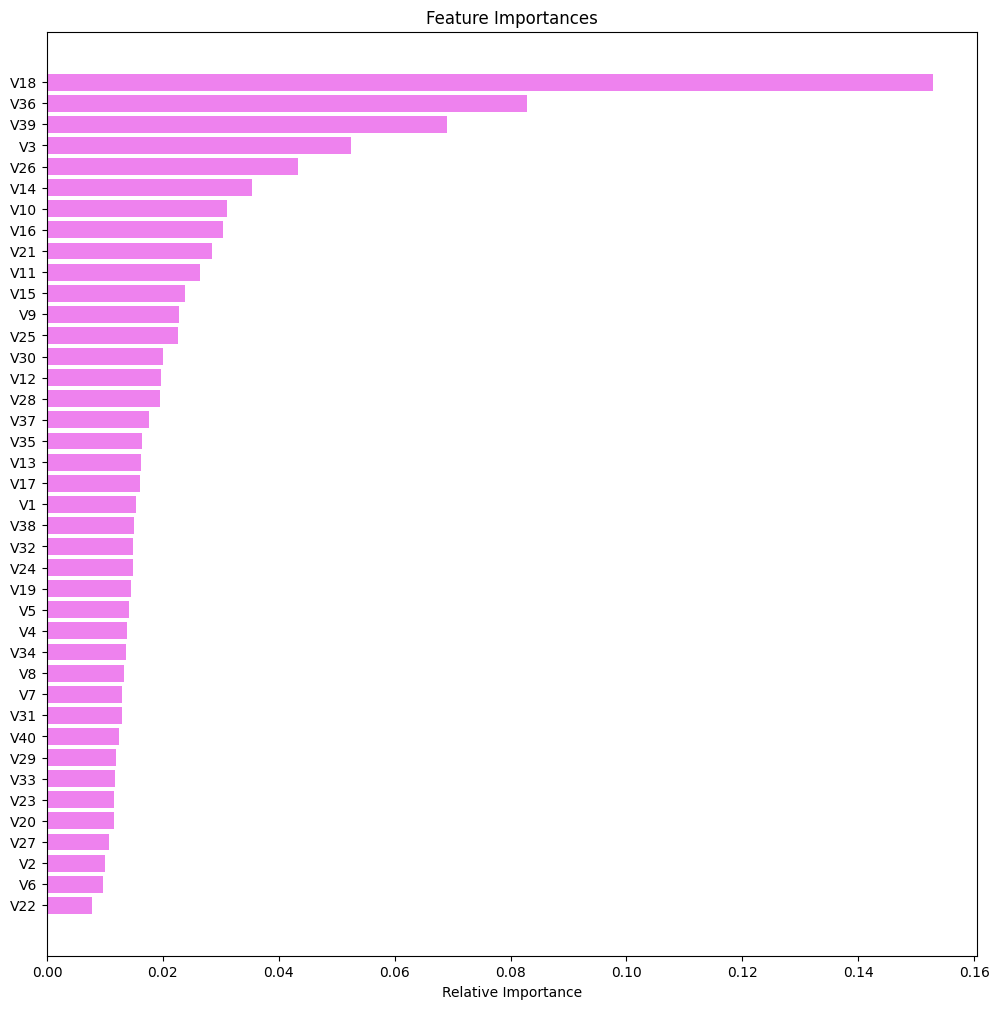

In [77]:
#C63
feature_names = df_backup.columns
feature_names = df_backup.drop(columns="Target").columns
importances = final_model.feature_importances_
indices = np.argsort(importances)

plt.figure(figsize=(12, 12))
plt.title("Feature Importances")
plt.barh(range(len(indices)), importances[indices], color="violet", align="center")
plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
plt.xlabel("Relative Importance")
plt.show()

The top attributes which have the maximum importance for making accurate failure / no-failure predictions are V18, V36, V39, V3, V26, and V14.

## Pipelines to build the final model


In [78]:
#C64
#  As we already know the final model, we will not be splitting train set into train and validation sets

X_train_pipeline = df.drop("Target", axis=1)
y_train_pipeline = df["Target"]

In [80]:
#C65
X_test_pipeline = df_test.drop("Target", axis=1)
y_test_pipeline = df_test["Target"]

In [84]:
#C66
model_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        (
            "XGB",
            XGBClassifier(
                subsample=0.9,
                scale_pos_weight=10,
                n_estimators=250,
                learning_rate=0.1,
                gamma=3,
                random_state=1,
                eval_metric="logloss",
            ),
        ),
    ]
)
# Fit the model on training data
print(model_pipeline.fit(X_train_pipeline, y_train_pipeline))

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('XGB',
                 XGBClassifier(base_score=None, booster=None, callbacks=None,
                               colsample_bylevel=None, colsample_bynode=None,
                               colsample_bytree=None, device=None,
                               early_stopping_rounds=None,
                               enable_categorical=True, eval_metric='logloss',
                               feature_types=None, feature_weights=None,
                               gamma=3, grow_policy=None, importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=None, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_con

In [83]:
#C67
#  transforming and predicting on test data
pipeline_score = Minimum_Vs_Model_cost(
    y_test_pipeline, model_pipeline.predict(X_test_pipeline)
)
print(pipeline_score)

0.7869767441860465


In [85]:
#C68
Minimum_Vs_Model_cost(y_test_pipeline, model_pipeline.predict(X_test_pipeline))

np.float64(0.7869767441860465)

The pipeline performance is as expected (Minimum_Vs_Model_cost ≈ 0.787), indicating it was built accurately to replicate the final chosen model after the necessary preprocessing.

## Business Insights and Conclusions
A machine learning model has been built to minimize the total maintenance cost of the machinery and processes used for wind-energy production.

The final tuned model (XGBoost) was chosen after evaluating seven algorithms on original, oversampled, and undersampled data, then tuning the strongest candidates with cross-validation and the custom cost-ratio metric.

A pipeline was built to productionize the final model (median imputation + tuned XGBoost). On the hold-out Test set the model achieves a Minimum_Vs_Model_cost of approximately 0.77, meaning its maintenance cost is about 1.31 times the theoretical minimum. Deploying the model therefore offers a clear cost advantage over having no predictive system.

The sensors with the greatest importance for separating failures from non-failures are V18, V36, V39, V3, V26, and V14. This ranking can guide any future effort to collect those signals more frequently or at higher resolution.

In [88]:
!jupyter nbconvert --to html "ReneWind_ScottHorning_Portfolio.ipynb"

[NbConvertApp] Converting notebook ReneWind_ScottHorning_Portfolio.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 47 image(s).
[NbConvertApp] Writing 2123104 bytes to ReneWind_ScottHorning_Portfolio.html
